In [194]:
%matplotlib inline
import sys, os, glob, timeit

from astropy.io import fits, ascii

import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.table import Table
import astropy.constants as const
from astropy.coordinates import SkyCoord, concatenate
from astropy import table
from astropy.wcs import WCS

from multiprocess import Pool


from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

In [195]:
import scienceplots

plt.style.use([ 'bright', 'science', 'no-latex', 'notebook'])

In [196]:
import pyqsofit
from pyqsofit.PyQSOFit import QSOFit
print(pyqsofit.__version__)

2.1.6


In [197]:
from scipy.stats import median_abs_deviation

In [198]:
flux_cal = False

## Setup PyQSOFit

In [199]:
path_ex = os.path.join('.')

# create a header
hdr0 = fits.Header()
hdr0['Author'] = 'Hengxiao Guo'
primary_hdu = fits.PrimaryHDU(header=hdr0)

### Conditions and Parameters

In [200]:
"""
In this table, we specify the priors / initial conditions and boundaries for the line fitting parameters.
"""

newdata = np.rec.array([
    (6564.61, 'Ha', 6400, 6800, 'Ha_br', 3, 0.0, 0.0, 1e10, 5e-3, 0.004/20, 0.05/20, 0.015, 0, 0, 0, 0.05/5, 1),
    (6564.61, 'Ha', 6400, 6800, 'Ha_na', 1, 0.0, 0.0, 1e10, 1e-3, 5e-4, 0.00169/10, 0.01, 1, 1, 0, 0.002, 1),
    (6549.85, 'Ha', 6400, 6800, 'NII6549', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169/10, 5e-3, 1, 1, 1, 0.001, 1),
    (6585.28, 'Ha', 6400, 6800, 'NII6585', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169/10, 5e-3, 1, 1, 1, 0.003, 1),
    (6718.29, 'Ha', 6400, 6800, 'SII6718', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169/10, 5e-3, 1, 1, 2, 0.001, 1),
    (6732.67, 'Ha', 6400, 6800, 'SII6732', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169/10, 5e-3, 1, 1, 2, 0.001, 1),

    (4862.68, 'Hb', 4640, 5100, 'Hb_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05/10, 0.01, 0, 0, 0, 0.01, 1),
    (4862.68, 'Hb', 4640, 5100, 'Hb_na', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169/10, 0.01, 1, 1, 0, 0.002, 1),
    (4960.30, 'Hb', 4640, 5100, 'OIII4959c', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169/10, 0.01, 1, 1, 0, 0.002, 1),
    (5008.24, 'Hb', 4640, 5100, 'OIII5007c', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169/10, 0.01, 1, 1, 0, 0.004, 1),
    (4960.30, 'Hb', 4640, 5100, 'OIII4959w',   1, 0.0, 0.0, 1e10, 3e-3, 2.3e-4, 0.004,  0.01,  2, 2, 0, 0.001, 1),
    (5008.24, 'Hb', 4640, 5100, 'OIII5007w',   1, 0.0, 0.0, 1e10, 3e-3, 2.3e-4, 0.004,  0.01,  2, 2, 0, 0.002, 1),
    #(4687.02, 'Hb', 4640, 5100, 'HeII4687_br', 1, 0.0, 0.0, 1e10, 5e-3, 0.004,  0.05,   0.005, 0, 0, 0, 0.001, 1),
    #(4687.02, 'Hb', 4640, 5100, 'HeII4687_na', 1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169, 0.005, 1, 1, 0, 0.001, 1),

    (4341.68, 'Hg', 4310, 4370, 'Hg_na',   1, 0.0, 0.0, 1e10, 1e-3, 2.3e-4, 0.00169/10,  0.01,  0, 1, 0, 0.002, 1),
    (4341.68, 'Hg', 4310, 4370, 'Hg_br',   1, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05/5, 0.01, 0, 0, 0, 0.01, 1),

    (3934.78, 'CaII', 3900, 3960, 'CaII3934' , 2, 0.0, 0.0, 1e10, 1e-3, 3.333e-4, 0.00169/10, 0.01, 99, 0, 0, -0.001, 1),

    (3728.48, 'OII', 3650, 3800, 'OII3728', 1, 0.0, 0.0, 1e10, 1e-3, 3.333e-4, 0.00169/10, 0.01, 1, 1, 0, 0.001, 1),

    (3426.84, 'NeV', 3380, 3480, 'NeV3426',    1, 0.0, 0.0, 1e10, 1e-3, 3.333e-4, 0.00169/10, 0.01, 0, 0, 0, 0.001, 1),
    (3426.84, 'NeV', 3380, 3480, 'NeV3426_br', 1, 0.0, 0.0, 1e10, 5e-3, 0.0025,   0.02,   0.01, 0, 0, 0, 0.001, 1),

    (2798.75, 'MgII', 2700, 2900, 'MgII_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05, 0.015, 0, 0, 0, 0.05, 1),
    (2798.75, 'MgII', 2700, 2900, 'MgII_na', 1, 0.0, 0.0, 1e10, 1e-3, 5e-4, 0.00169/2, 0.01, 1, 1, 0, 0.002, 1),

    (1908.73, 'CIII', 1700, 1970, 'CIII_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05/5, 0.015, 99, 0, 0, 0.01, 1),
    #(1908.73, 'CIII', 1700, 1970, 'CIII_na',   1, 0.0, 0.0, 1e10, 1e-3, 5e-4,  0.00169, 0.01,  1, 1, 0, 0.002, 1),
    #(1892.03, 'CIII', 1700, 1970, 'SiIII1892', 1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.003, 1, 1, 0, 0.005, 1),
    #(1857.40, 'CIII', 1700, 1970, 'AlIII1857', 1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.003, 1, 1, 0, 0.005, 1),
    #(1816.98, 'CIII', 1700, 1970, 'SiII1816',  1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.01,  1, 1, 0, 0.0002, 1),
    #(1786.7,  'CIII', 1700, 1970, 'FeII1787',  1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.01,  1, 1, 0, 0.0002, 1),
    #(1750.26, 'CIII', 1700, 1970, 'NIII1750',  1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.01,  1, 1, 0, 0.001, 1),
    #(1718.55, 'CIII', 1700, 1900, 'NIV1718',   1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015,  0.01,  1, 1, 0, 0.001, 1),

    (1549.06, 'CIV', 1500, 1700, 'CIV_br', 2, 0.0, 0.0, 1e10, 5e-3, 0.004, 0.05/5, 0.015, 0, 0, 0, 0.05, 1),
    # (1549.06, 'CIV', 1500, 1700, 'CIV_na', 1, 0.0, 0.0, 1e10, 1e-3, 5e-4, 0.00169, 0.01, 1, 1, 0, 0.002, 1),
    #(1640.42, 'CIV', 1500, 1700, 'HeII1640',    1, 0.0, 0.0, 1e10, 1e-3, 5e-4,   0.00169, 0.008, 1, 1, 0, 0.002, 1),
    #(1663.48, 'CIV', 1500, 1700, 'OIII1663',    1, 0.0, 0.0, 1e10, 1e-3, 5e-4,   0.00169, 0.008, 1, 1, 0, 0.002, 1),
    #(1640.42, 'CIV', 1500, 1700, 'HeII1640_br', 1, 0.0, 0.0, 1e10, 5e-3, 0.0025, 0.02,   0.008, 1, 1, 0, 0.002, 1),
    #(1663.48, 'CIV', 1500, 1700, 'OIII1663_br', 1, 0.0, 0.0, 1e10, 5e-3, 0.0025, 0.02,   0.008, 1, 1, 0, 0.002, 1),

    (1402.06, 'SiIV', 1290, 1450, 'SiIV_OIV1', 1, 0.0, 0.0, 1e10, 5e-3, 0.002, 0.05,  0.015, 1, 1, 0, 0.05, 1),
    (1396.76, 'SiIV', 1290, 1450, 'SiIV_OIV2', 1, 0.0, 0.0, 1e10, 5e-3, 0.002, 0.05,  0.015, 1, 1, 0, 0.05, 1),
    #(1335.30, 'SiIV', 1290, 1450, 'CII1335',   1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015, 0.01,  1, 1, 0, 0.001, 1),
    #(1304.35, 'SiIV', 1290, 1450, 'OI1304',    1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.015, 0.01,  1, 1, 0, 0.001, 1),

    (1215.67, 'Lya', 1150, 1290, 'Lya_br', 3, 0.0, 0.0, 1e10, 5e-3, 0.002, 0.05, 0.02, 0, 0, 0, 0.05, 1),
    (1240.14, 'Lya', 1150, 1290, 'NV1240', 1, 0.0, 0.0, 1e10, 2e-3, 0.001, 0.01, 0.005, 0, 0, 0, 0.002, 1),
    (1215.67, 'Lya', 1150, 1290, 'Lya_na', 1, 0.0, 0.0, 1e10, 1e-3, 5e-4, 0.00169, 0.01, 0, 0, 0, 0.002, 1),
    ],

    formats='float32,    a20,  float32, float32,      a20,  int32, float32, float32, float32, float32, float32, float32, float32,   int32,  int32,  int32, float32, int32',
    names=' lambda, compname,   minwav,  maxwav, linename, ngauss,  inisca,  minsca,  maxsca,  inisig,  minsig,  maxsig,    voff,  vindex, windex, findex,  fvalue,  vary')

# Header
hdr1 = fits.Header()
hdr1['lambda'] = 'Vacuum Wavelength in Ang'
hdr1['minwav'] = 'Lower complex fitting wavelength range'
hdr1['maxwav'] = 'Upper complex fitting wavelength range'
hdr1['ngauss'] = 'Number of Gaussians for the line'

# Can be set to negative for absorption lines if you want
hdr1['inisca'] = 'Initial guess of line scale [flux]'
hdr1['minsca'] = 'Lower range of line scale [flux]'
hdr1['maxsca'] = 'Upper range of line scale [flux]'

hdr1['inisig'] = 'Initial guess of linesigma [lnlambda]'
hdr1['minsig'] = 'Lower range of line sigma [lnlambda]'
hdr1['maxsig'] = 'Upper range of line sigma [lnlambda]'

hdr1['voff  '] = 'Limits on velocity offset from the central wavelength [lnlambda]'
hdr1['vindex'] = 'Entries w/ same NONZERO vindex constrained to have same velocity'
hdr1['windex'] = 'Entries w/ same NONZERO windex constrained to have same width'
hdr1['findex'] = 'Entries w/ same NONZERO findex have constrained flux ratios'
hdr1['fvalue'] = 'Relative scale factor for entries w/ same findex'

hdr1['vary'] = 'Whether or not to vary the parameter (set to 0 to fix the line parameter to initial values)'

# Save line info
hdu1 = fits.BinTableHDU(data=newdata, header=hdr1, name='line_priors')

In [201]:
"""
In this table, we specify the windows and priors / initial conditions and boundaries for the continuum fitting parameters.
"""

conti_windows = np.rec.array([
    (900., 1170.), 
    (1275., 1290.),
    (1350., 1360.),
    (1445., 1540.), # modified
    (1690., 1705.),
    (1770., 1810.),
    (1970., 2400.),
    (2480., 2700.), # modified 2
    (2925., 3400.),
    (3500., 3610.),
    (3775., 3832.),
    (4000., 4050.),
    (4200., 4230.),
    (4435., 4755.), # modified
    (5100., 6400.),  # modified 3 The He line is not strong
    #(6005., 6035.), # modified 3
    #(6110., 6250.), # modified 3
    (6750., 7000.), # modified
    (7160., 7180.),
    (7500., 7800.),
    (8050., 8150.), # Continuum fitting windows (to avoid emission line, etc.)  [AA]
    ], 
    formats = 'float32,  float32',
    names =    'min,     max')

hdu2 = fits.BinTableHDU(data=conti_windows, name='conti_windows')

conti_priors = np.rec.array([
    ('Fe_uv_norm',  0.0,   0.0,   1e10,  1), # Normalization of the MgII Fe template [flux]
    ('Fe_uv_FWHM',  3000,  1200,  18000, 1), # FWHM of the MgII Fe template [AA]
    ('Fe_uv_shift', 0.0,   -0.01, 0.01,  1), # Wavelength shift of the MgII Fe template [lnlambda]
    ('Fe_op_norm',  0.0,   0.0,   1e10,  1), # Normalization of the Hbeta/Halpha Fe template [flux]
    ('Fe_op_FWHM',  3000,  1200,  18000, 1), # FWHM of the Hbeta/Halpha Fe template [AA]
    ('Fe_op_shift', 0.0,   -0.01, 0.01,  1), # Wavelength shift of the Hbeta/Halpha Fe template [lnlambda]
    ('PL_norm',     1.0,   0.0,   1e8,  1), # Normalization of the power-law (PL) continuum f_lambda = (lambda/3000)^-alpha
    ('PL_slope',    -1.5,  -5.0,  3.0,   1), # Slope of the power-law (PL) continuum
    ('Blamer_norm', 0.0,   0.0,   1e10,  1), # Normalization of the Balmer continuum at < 3646 AA [flux] (Dietrich et al. 2002)
    ('Balmer_Te',   15000, 10000, 50000, 1), # Te of the Balmer continuum at < 3646 AA [K?]
    ('Balmer_Tau',  0.5,   0.1,   2.0,   1), # Tau of the Balmer continuum at < 3646 AA
    ('conti_a_0',  0, -1e10, 1e2,  1), # 1st coefficient of the polynomial continuum
    ('conti_a_1',  0, -1e10, 1e2,  1), # 2nd coefficient of the polynomial continuum
    ('conti_a_2',  0, -1e10, 1e2,  1), # 3rd coefficient of the polynomial continuum
    # TODO: In a future version, we may add options to add more if you want...
    # ('conti_pl_3',  0.0,  -1e10,  1e10,  1), # 4th coefficient of the polynomial continuum
    # ('conti_pl_4',  0.0,  -1e10,  1e10,  1), # 5th coefficient of the polynomial continuum
    ],

    formats = 'a20,  float32, float32, float32, int32',
    names = 'parname, initial,   min,     max,     vary')

hdr3 = fits.Header()
hdr3['ini'] = 'Initial guess of line scale [flux]'
hdr3['min'] = 'FWHM of the MgII Fe template'
hdr3['max'] = 'Wavelength shift of the MgII Fe template'

hdr3['vary'] = 'Whether or not to vary the parameter (set to 0 to fix the continuum parameter to initial values)'


hdu3 = fits.BinTableHDU(data=conti_priors, header=hdr3, name='conti_priors')

In [202]:
"""
In this table, we allow user to customized some key parameters in our result measurements.
"""
cont_loc = [1350, 1450, 2200, 3000, 4200, 5100]
BC =       [9.26, 9.26, 9.26, 5.15, 5.15, 3.81]
measure_info = Table(
    [
        [[1350, 1450, 2200, 3000, 4200, 5100]],
        [[
            # [2240, 2650], 
            [4435, 4685],
        ]]
    ],
    names=([
        'cont_loc',
        'Fe_flux_range'
    ]),
    dtype=([
        'float32',
        'float32'
    ])
)
hdr4 = fits.Header()
hdr4['cont_loc'] = 'The wavelength of continuum luminosity in results'
hdr4['Fe_flux_range'] = 'Fe emission wavelength range calculated in results'

hdu4 = fits.BinTableHDU(data=measure_info, header=hdr4, name='measure_info')

hdu_list = fits.HDUList([primary_hdu, hdu1, hdu2, hdu3, hdu4])
hdu_list.writeto('qsopar.fits', overwrite=True)

## Fit the spectra

In [203]:
data_agn_updated = ascii.read('local_agn_updated.txt')

ra, dec = data_agn_updated['ra'], data_agn_updated['dec']
data_coords = SkyCoord(ra, dec, unit=[u.deg, u.deg])

data_agn_updated['err_reason'] = False

In [204]:
data_agn_updated

ra,dec,z,logMs,ID,id,RA,DEC,z_simb,r_z_simb,z_best,err_reason
float64,float64,float64,float64,int64,int64,float64,float64,float64,str19,float64,bool
0.47615,0.125693,0.1395,9.885926339801431,0,0,0.47615,0.125693,0.13954,2015ApJS..219...12A,0.13954,False
2.36003,0.325606,0.1138,9.468347330412158,1,1,2.36003,0.325606,-1.0,--,0.1138,False
4.27033,-0.493348,0.0672,9.970811610872518,2,2,4.27033,-0.493348,0.06716,2012ApJS..203...21A,0.06716,False
6.96605,0.794382,0.0821,9.79657433321043,3,3,6.96605,0.794382,0.08207,2012ApJS..203...21A,0.08207,False
8.39416,0.048925,0.1067,9.90471554527868,4,4,8.39416,0.048925,0.10677,2009ApJS..182..543A,0.10677,False
8.15918,-1.009817,0.0917,9.961421094066448,5,5,8.15918,-1.009817,0.09172,2012ApJS..203...21A,0.09172,False
11.38946,-0.969121,0.1376,9.869231719730976,6,6,11.38946,-0.969121,0.1376,2012ApJS..203...21A,0.1376,False
11.51401,0.636591,0.1246,9.58092497567562,7,7,11.51401,0.636591,-1.0,--,0.1246,False
14.01926,0.59255,0.056,9.889861721258189,8,8,14.01926,0.59255,0.056,2023ApJS..267...17L,0.056,False


Pipeline to loop through each source, get the spectrum (if there is one), and fit it.

### MBH Calculation Function

In [205]:
def calc_M_BH_vir(logL, FWHM_line, sigma_disp=69, line_name='Ha', method='conti'):
    """
    Calculate the single-epoch (virial) black hole mass from the
    continuum luminosity and broad line FWHM
    
    Parameter:
    ----------
    logL: float
        log10 of the continuum or broad-line line luminosity in erg / s
        
    sigma_res: float
        instrumental dispersion in km / s

    line_name: str

    method: str
    
    Return:
    -----------
    Computed black hole mass M_BH,vir in Solar masses    
    
    "This approach assumes that the broad-line region (BLR)
    is virialized, the continuum luminosity is used as a proxy
    for the BLR radius, and the broad line width (FWHM) is used
    as a proxy for the virial velocity." -- Shen et al. (2011)
    """
    
    key = line_name.split('_')[0] # Remove the _br

    if method == 'line-rv15':
        return np.log10(1.075) + 6.57 + 0.47*(logL - 42) + 2.06*np.log10(FWHM_line/1e3)

    if method == 'conti':
        
        #    VP06           S11            VP06
        a = {'Hb': 0.910 , 'MgII': 0.740, 'CIV':0.660}
        b = {'Hb': 0.50,   'MgII': 0.62,  'CIV':0.53}

    elif method == 'line':

        a = {'Ha': 0.379, 'Hb': 1.63 , 'MgII': 1.70, 'CIV':1.52}
        b = {'Ha': 0.43,  'Hb': 0.49,  'MgII': 0.63, 'CIV':0.46}
        
    c = {'Ha': 2.1,   'Hb': 2,     'MgII': 2,    'CIV':2}
    logLs = {'Ha': 42, 'Hb': 44, 'MgII': 44, 'CIV':44}
    lambda0 = {'Ha': 6564.61, 'Hb': 4862.68, 'MgII': 2798.75, 'CIV': 1549.06}
    
    # Subtract component from instrumental broadening
    FWHM_disp = 1/const.c.to(u.km/u.s).value * sigma_disp * lambda0[key]
    FWHM = np.sqrt(FWHM_line**2 - FWHM_disp**2)
    
    return a[key] + b[key]*(logL-logLs[key]) + c[key]*np.log10(FWHM)

### Flux Calibration Function

In [206]:
import pickle

def flux_calib(ID, wave, flux, flux_err, src):

    if flux_cal == False:
        return flux, flux_err, 0

    else:

        # Convert spectrum to photometry
        # bands: 
        filter_dir = '/Users/diegomiura/dwarf_agn_cosmos/des/cigale-v2022.1/pcigale/data/filters'
    
        #TODO: Add y, JHK
        #bands = ['ctio.decam.u', 'ctio.decam.g', 'ctio.decam.r', 'ctio.decam.i', 'ctio.decam.z', 'vista.vircam.J', 'vista.vircam.H', 'vista.vircam.Ks']
        bands = ['u_prime', 'g_prime', 'r_prime', 'i_prime', 'z_prime', 'vista.vircam.J', 'vista.vircam.H', 'vista.vircam.Ks']


        # Get the COSMOS2020 photometry

        dat_phot = Table.read('/Users/diegomiura/dwarf_agn_cosmos/cigale/des/data_phot.dat', format='ascii')
        dat_phot['u_prime'] = dat_phot['ctio.decam.u']
        dat_phot['g_prime'] = dat_phot['ctio.decam.g']
        dat_phot['r_prime'] = dat_phot['ctio.decam.r']
        dat_phot['i_prime'] = dat_phot['ctio.decam.i']
        dat_phot['z_prime'] = dat_phot['ctio.decam.z']
        dat_phot['u_prime_err'] = dat_phot['ctio.decam.u_err']
        dat_phot['g_prime_err'] = dat_phot['ctio.decam.g_err']
        dat_phot['r_prime_err'] = dat_phot['ctio.decam.r_err']
        dat_phot['i_prime_err'] = dat_phot['ctio.decam.i_err']
        dat_phot['z_prime_err'] = dat_phot['ctio.decam.z_err']
        #### ...
            
        rs = np.full(len(bands), np.nan)
        fluxes_e = np.full(len(bands), np.nan)
    
        # Convert cigale filter to pyphot filter and get the spectrophotometric flux
        for i, band in enumerate(bands):
    
            with open(os.path.join(filter_dir, f'name={band}.pickle'), 'rb') as pickle_file:
                filter_ = pickle.load(pickle_file)
                wl = filter_.wl
                tr = filter_.tr
                lambda_piv = filter_.pivot
            # Convert flux 
            mask_f = np.isfinite(flux) & (flux > 0)
            print(len(flux[mask_f]))
            #f_l = (flux[mask_f]*1e-17*u.erg/u.s/u.cm**2/u.AA).to(u.W/u.m**2/u.nm, equivalencies=u.spectral_density(wave[mask_f]*u.AA)).value
            # Interpolate to a grid
            print('I got here')
            if (len(flux[mask_f]) > 0):
                print('I got here 2')
                if (np.min(wave[mask_f]/10) < lambda_piv-20) & (np.max(wave[mask_f]/10) > lambda_piv+20):
                    print('I got here 3')
                    f_l = (flux[mask_f]*1e-17*u.erg/u.s/u.cm**2/u.AA).to(u.W/u.m**2/u.nm, equivalencies=u.spectral_density(wave[mask_f]*u.AA)).value
                    wl_grid = np.arange(np.min(wave[mask_f]/10), np.max(wave[mask_f]/10), 1)
                    tr_grid = np.interp(wl_grid, wl, tr)
                    f_l_grid = np.interp(wl_grid, wave[mask_f]/10, f_l)
                    # # Fλ flux density in W/m²/nm
                    # We compute directly Fν from ∫T×Fλ×dλ
                    # Normalisation is such that the results we obtain are directly in mJy
                    # https://gitlab.lam.fr/cigale/cigale/-/blob/master/pcigale/sed/__init__.py?ref_type=heads
                    flux_spectro = np.trapz(tr_grid * f_l_grid, x=wl_grid)
                    print('flux_spectro', flux_spectro)
                    #plt.errorbar(np.mean(wl), flux_spectro, marker='o', markersize=20, color='gray')
                    ft = (flux[mask_f]*1e-17*u.erg/u.s/u.cm**2/u.AA).to(u.mJy, equivalencies=u.spectral_density(wave[mask_f]*u.AA)).value
                    #plt.plot(wl_grid, np.interp(wl_grid, wave[mask_f]/10, ft), color='k')
                    # Get photometry
                    if ID in dat_phot['id']:
                        print('I got here 4')
                        print('have photometry')
                        flux_band = dat_phot[band][dat_phot['id']==ID][0]
                        fe = dat_phot[band+'_err'][dat_phot['id']==ID][0]
                        if fe > 0:
                            plt.errorbar(np.mean(wl), flux_band, yerr=fe, marker='o', markersize=20, color='orange')
                        print(band)
                        print('flux-band:',flux_band)
                        print('flux_e-band:',fe)
                        print('flux-spectro-band:',flux_spectro)
                        if (len(dat_phot[band][dat_phot['id']==ID]) > 0) & (fe > 0):
                            fluxes_e[i] = fe
                        if (flux_band > 0) & (flux_spectro > 0):
                            rs[i] = flux_band/flux_spectro
                    else:
                        print('NO COSMOS2020 optical PHOTOMETRY')
                        data_agn_updated['err_reason'][ID-1] = 'NO COSMOS2020 optical PHOTOMETRY'
                        return flux, flux_err, 0
    
        # TODO: flag unable to flux calibrate error weighted
        mask = (rs > 0) & np.isfinite(rs) & np.isfinite(fluxes_e)
        if len(rs[mask]) == 0:
            print(f'WARNING: unable to flux calibrate {ID}')
            data_agn_updated['err_reason'][ID-1] = 'Flux Calibration'
            return flux, flux_err, 0
        r = np.average(rs[mask], weights=1/fluxes_e[mask])
        print('flux-weighted mean:',r)
        print('rs:',rs[mask])
        
        plt.plot(wl_grid, np.interp(wl_grid, wave[mask_f]/10, ft)*r, color='r')
        plt.title(f'ID: {ID} Survey: {src}')
        plt.show()

        # TODO: Flag unable to flux calibrate
        return flux*r, flux_err*r, 1

In [207]:
dat_phot = Table.read('../cigale/local/data_phot.dat', format='ascii')

dat_phot

ra,dec,z,logMs,ID,id,RA,DEC,z_simb,r_z_simb,z_best,z_before,z_after,pointlike,inMzLSBASS,goodfitsLS,isolatedLS,W34_blended,galex.FUV,galex.NUV,galex.FUV_err,galex.NUV_err,sdss.gp,sdss.rp,sdss.ip,sdss.zp,sdss.gp_err,sdss.rp_err,sdss.ip_err,sdss.zp_err,90prime_r,90prime_g,zd_mosaic,90prime_r_err,zd_mosaic_err,90prime_g_err,vista.vircam.Y,vista.vircam.J,vista.vircam.H,vista.vircam.Ks,vista.vircam.Y_err,vista.vircam.J_err,vista.vircam.H_err,vista.vircam.Ks_err,WFCAM_Y,WFCAM_J,WFCAM_H,WFCAM_K,WFCAM_Y_err,WFCAM_J_err,WFCAM_H_err,WFCAM_K_err,WISE1_origin,WISE1,WISE1_err,WISE2_origin,WISE2,WISE2_err,WISE34_origin,WISE3,WISE3_err,WISE4,WISE4_err,redshift
float64,float64,float64,float64,int64,int64,float64,float64,float64,str19,float64,float64,float64,str5,str5,str5,str5,str5,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str7,float64,float64,str7,float64,float64,str7,float64,float64,float64,float64,float64
0.47615,0.125693,0.1395,7690000000.0,0,0,0.47615,0.125693,0.13954,2015ApJS..219...12A,0.13954,0.1395,0.13954,False,False,False,True,False,-9.9e+27,0.020200524525697143,-9.9e+27,0.003901308300114176,0.0993800080469154,0.16793652931032832,0.2508588303431637,0.26427141760051304,0.0003422927294391881,0.00035285260987921187,0.0008437730749854024,0.0017487103234044357,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,0.3274383928380289,0.4141888466911869,0.5268614223635384,-99.0,0.0050774942158207685,0.008270380263168476,0.011296824632101393,0.2550054439433998,0.3137101656056705,0.3690460233885413,0.46346296532011266,0.00598681865899897,0.007359124644737259,0.014572617188652794,0.017102354310224298,LS10,0.37096283919157214,0.0021927123503009223,LS10,0.32291755954671914,0.003911321357335581,LS10,0.5668711580194675,0.058480754825599036,3.2316241433718105,0.27331063039447406,0.1395
2.36003,0.325606,0.1138,2940000000.0,1,1,2.36003,0.325606,-1.0,--,0.1138,0.1138,0.1138,True,False,True,False,True,-9.9e+27,0.06639390221822428,-9.9e+27,-0.06639390221822428,0.06958377398822267,0.0909990034883374,0.12573150872162211,0.12861199062837447,9.128542963899074e-05,0.00011233400485817162,0.00019758848264441627,0.0002371313196177655,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,0.14635770810022092,0.17256996062072966,0.17874734508828763,-99.0,0.004062574407196485,0.00488183569564933,0.0059051583489335285,0.11161670230002396,0.14862376594448617,0.15526717009145746,-99.0,0.004051939911331296,0.006120119605735774,0.009667338021753792,-99.0,LS10UL,0.22862211253667486,-0.22862211253667486,LS10UL,0.27652009332160965,-0.27652009332160965,AllWISE,0.8588476282120958,-0.8588476282120958,5700.0,-5700.0,0.1138
4.27033,-0.493348,0.0672,9350000000.0,2,2,4.27033,-0.493348,0.06716,2012ApJS..203...21A,0.06716,0.0672,0.06716,False,False,True,True,False,-9.9e+27,0.06510329644668547,-9.9e+27,-0.06510329644668547,0.4731660379431854,0.8811518693689282,1.105042745049613,1.327821880297241,0.0002833550546606602,0.00046598205207860964,0.0008184126981808236,0.0012663848134143831,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.460917192452811,1.7832868209048396,1.6831437160268854,-99.0,0.007634371078156159,0.009262855572027981,0.0123539645336053,1.165965395344351,1.427626689169144,1.7562897309074,-99.0,0.010234355854884695,0.014040163787361433,0.01668647163650924,-99.0,LS10,0.8949884278377879,0.002836881728215233,LS10,0.6390439917740418,0.004455978778432764,LS10,1.4669635522164197,0.05829461583691962,1.6995161410204218,0.2711928428046316,0.0672
6.96605,0.794382,0.0821,6260000000.0,3,3,6.96605,0.794382,0.08207,2012ApJS..203...21A,0.08207,0.0821,0.08207,False,False,True,True,False,-9.9e+27,0.062006133286140054,-9.9e+27,0.004738558001922147,0.3479504150751596,0.5413521680581335,-99.0,0.7224371677026326,0.000137750523742614,0.0005397274563535347,-99.0,0.0021142965827119884,-99.0,-99.0

In [208]:
import pyqsofit
pyqsofit.__version__

'2.1.6'

### Use fit & MBH equation function to calculate MBH for each AGN

In [209]:
def calc_M_BH_vir(logL, FWHM_line, sigma_disp=69, line_name='Ha', method='conti'):
    """
    Calculate the single-epoch (virial) black hole mass from the
    continuum luminosity and broad line FWHM
    
    Parameter:
    ----------
    logL: float
        log10 of the continuum or broad-line line luminosity in erg / s
        
    sigma_res: float
        instrumental dispersion in km / s

    line_name: str

    method: str
    
    Return:
    -----------
    Computed black hole mass M_BH,vir in Solar masses    
    
    "This approach assumes that the broad-line region (BLR)
    is virialized, the continuum luminosity is used as a proxy
    for the BLR radius, and the broad line width (FWHM) is used
    as a proxy for the virial velocity." -- Shen et al. (2011)
    """
    
    key = line_name.split('_')[0] # Remove the _br

    if method == 'line-rv15':
        return np.log10(1.075) + 6.57 + 0.47*(logL - 42) + 2.06*np.log10(FWHM_line/1e3)

    if method == 'conti':
        
        #    VP06           S11            VP06
        a = {'Hb': 0.910 , 'MgII': 0.740, 'CIV':0.660}
        b = {'Hb': 0.50,   'MgII': 0.62,  'CIV':0.53}

    elif method == 'line':

        a = {'Ha': 0.379, 'Hb': 1.63 , 'MgII': 1.70, 'CIV':1.52}
        b = {'Ha': 0.43,  'Hb': 0.49,  'MgII': 0.63, 'CIV':0.46}
        
    c = {'Ha': 2.1,   'Hb': 2,     'MgII': 2,    'CIV':2}
    logLs = {'Ha': 42, 'Hb': 44, 'MgII': 44, 'CIV':44}
    lambda0 = {'Ha': 6564.61, 'Hb': 4862.68, 'MgII': 2798.75, 'CIV': 1549.06}
    
    # Subtract component from instrumental broadening
    FWHM_disp = 1/const.c.to(u.km/u.s).value * sigma_disp * lambda0[key]
    FWHM = np.sqrt(FWHM_line**2 - FWHM_disp**2)
    
    return a[key] + b[key]*(logL-logLs[key]) + c[key]*np.log10(FWHM)

In [210]:
bad_ID =[]

def measureMBH(ID, src, z, wave, flux, flux_err):
    
    fill = np.full(len(data_agn_BH.colnames)-1, -1.0)
    # Add a row to the table
    data_agn_BH.add_row(np.concatenate(([ID], fill)))
    
    name = 'rev_ID = '+str(ID) + ',' + str(src)

    #plt.plot(wave, flux)
    #plt.plot(wave, flux_err)

    #if (ID == 26) or (ID == 490) or (ID == 482) or (ID == 404):
    if False:
        # Special 
        # Visual inspection reveals host only.
        q = QSOFit(wave, flux, flux_err, z, path=path_ex)
        q.Fit(name=name, nsmooth=1, deredden=True, reject_badpix=True,  #wave_range= np.array([1000, 11000]), \
              wave_mask=None, decompose_host=True, BC=False, npca_gal=15, npca_qso=1, \
              Fe_uv_op=False, poly=True, rej_abs_conti=True, rej_abs_line=True, MC=True, nsamp=4, linefit=True, \
              plot_fig=False, save_result=False, kwargs_plot={'save_fig_path': '.', 'plot_br_prop':True},
              save_fits_name=None, verbose=False, save_fig=True, param_file_name='qsopar.fits')
    else:
    
    #TODO: Testing 'FAILED to FIT'

        # Prepare data
        #try:
        #q_noFeII = QSOFit(wave, flux, flux_err, z, path=path_ex)
        #q_noFeII.Fit(name=name, nsmooth=1, deredden=True, reject_badpix=True,  #wave_range= np.array([1000, 11000]), \
        #    wave_mask=None, decompose_host=True, BC=False, npca_gal=5, npca_qso=5, \
        #    Fe_uv_op=False, poly=True, rej_abs_conti=False, rej_abs_line=True, MC=True, nsamp=4, linefit=True, \
        #    plot_fig=False, save_result=False, kwargs_plot={'save_fig_path': '.', 'plot_br_prop':True},
        #    save_fits_name=None, verbose=False, save_fig=True, param_file_name='qsopar.fits')
        #except:
        #    plt.plot(wave, flux)
        #    plt.plot(wave, flux_err)
        #    data_agn_updated['err_reason'][ID-1] = 'Failed to fit'
        #    print(f'FAILED TO FIT ID: {ID}')
        #    bad_ID.append(ID)
        #    return
        
        ## IF the chi2 is really bad > 10, remove Fe II and try again
        q_FeII = QSOFit(wave, flux, flux_err, z, path=path_ex)
        q_FeII.Fit(name=name, nsmooth=1, deredden=True, reject_badpix=True,  #wave_range= np.array([1000, 11000]), \
                wave_mask=None, decompose_host=True, BC=False, npca_gal=5, npca_qso=5, \
                Fe_uv_op=True, poly=True, rej_abs_conti=True, rej_abs_line=True, MC=True, nsamp=4, linefit=True, \
                plot_fig=False, save_result=False, kwargs_plot={'save_fig_path': '.', 'plot_br_prop':True},
                save_fits_name=None, verbose=False, save_fig=True, param_file_name='qsopar.fits')

        ## Use Fe II it if chi2 improves by ~20%
        #if (q_noFeII.conti_fit.redchi - q_FeII.conti_fit.redchi)/q_FeII.conti_fit.redchi > 0.2:
        #    q = q_FeII
        #    print('use Fe ii')
        #else:
        #    q = q_noFeII
        q = q_FeII

    # TODO: consider error 
    Lconti = -1
    Lbol = -1

    data_agn_BH['SNR'][-1] = q.SN_ratio_conti
    data_agn_BH['src'][-1] = src

    data_agn_BH['f_conti'][-1] = np.median(q.PL_poly_BC/q.host)
    
    try:
        if ID==290: ##### !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
            fig, ax = plt.subplots(figsize=(15, 5))

            # Plot the quasar rest frame spectrum after removed the host galaxy component
            ax.plot(q.wave, q.Smooth(q.flux, 8), 'k', label='Data', lw=1)
            
            # Skip the error results before plotting
            if q.MCMC == True:
                gauss_result = q.gauss_result[::2]
            else:
                gauss_result = q.gauss_result

            # Plot individual line components
            br_tot = np.zeros_like(q.wave)
            na_tot = np.zeros_like(q.wave)
            for p in range(int(len(gauss_result) / 3)):
                if q.CalFWHM(gauss_result[3 * p + 2]) > 1200:  # < 1200 km/s narrow
                    br_tot += q.Onegauss(np.log(q.wave), gauss_result[p * 3:(p + 1) * 3])
                else:
                    na_tot += q.Onegauss(np.log(q.wave), gauss_result[p * 3:(p + 1) * 3])
            ax.plot(q.wave, br_tot + q.f_conti_model, color='r', label='Broad Model', zorder=100)
            ax.plot(q.wave, na_tot + q.f_conti_model, color='g', label='Narrow Model', zorder=99)
            
            # To plot the whole model, we use Manygauss to show the line fitting results saved in gauss_result
            ax.plot(q.wave, q.Manygauss(np.log(q.wave), gauss_result) + q.f_conti_model, 'b', label='Total Model', lw=3.5, zorder=98)
            ax.plot(q.wave, q.PL_poly_BC, 'orange', lw=2, label='Continuum')
            ax.plot(q.wave, q.qso, 'pink', lw=2, label='Host+QSO Template')
            ax.plot(q.wave, q.host, 'm', lw=2, label='Host')
            plt.legend(fontsize=12, loc=4, frameon=True)
            
            ax.set_xlabel(r'$\rm Rest \, Wavelength$ ($\rm \AA$)', fontsize=20)
            ax.set_ylabel(r'$\rm f_{\lambda}$ ($\rm 10^{-17} erg\;s^{-1}\;cm^{-2}\;\AA^{-1}$)', fontsize=20)

            line_cen = np.array(
                [6564.60, 6549.85, 6585.27, 6718.29, 6732.66, 4862.68, 5008.24, 4687.02, 4341.68, 3934.78, 3728.47,
                 3426.84, 2798.75, 1908.72, 1816.97, 1750.26, 1718.55, 1549.06, 1640.42, 1402.06, 1396.76, 1335.30, \
                 1215.67])
            
            line_name = np.array(
                ['', '', r'H$\alpha$+[NII]', '', '[SII]6718,6732', r'H$\beta$', '[OIII]', 'HeII4687', r'H$\gamma$', 'CaII3934', '[OII]3728',
                 'NeV3426', 'MgII', 'CIII]', 'SiII1816', 'NIII]1750', 'NIV]1718', 'CIV', 'HeII1640', '', 'SiIV+OIV',
                 'CII1335', r'Ly$\alpha$'])
            
            ax.set_ylim(-1.8, 8.4)
            
            # Line position
            axis_to_data = ax.transAxes + ax.transData.inverted()
            points_data = axis_to_data.transform((0, 0.92))

            for ll in range(len(line_cen)):
                if q.wave.min() < line_cen[ll] < q.wave.max():
                    ax.axvline(line_cen[ll], color='k', linestyle=':')
                    # ax.plot([line_cen[ll], line_cen[ll]], ylims, 'k:')
                    ax.text(line_cen[ll] + 7, points_data[1], line_name[ll], rotation=90, fontsize=10, va='top')

            ax.set_xlim(np.min(q.wave), np.max(q.wave))
            fig.tight_layout()
            fig.savefig(f'spec{src}.pdf', dpi=300)
            
        ###
        q.plot_fig(plot_br_prop=True, save_fig_path='fits')
        plt.show()
    except:
        ## DEBUG
        data_agn_updated['err_reason'][ID-1] = 'Bad Spec'
        print('bad spec!')

    for k, c in enumerate(cont_loc):
        Lconti = float(q.conti_result[q.conti_result_name==f'L{c}'][0])
        if Lconti > 0:
            data_agn_BH['Lconti'][-1] = Lconti
        print(c, q.conti_result[q.conti_result_name==f'L{c}'])
        Lbol = np.log10(BC[k]*10**Lconti)
        if Lbol > 0:
            data_agn_BH['Lbol'][-1] = Lbol

            
    snr_Has = []
    snr_Hbs = []
    snr_MgIIs = []
    snr_CIVs = []

    M_BH_Hbs = []
    M_BH_MgIIs = []
    M_BH_CIVs = []

    M_BH_Has_rv_line = []
    M_BH_Has_line = []
    M_BH_Hbs_line = []
    M_BH_MgIIs_line = []
    M_BH_CIVs_line = []

    Lconti = data_agn_BH['Lconti'][-1]
    print('Lconti', Lconti)

    for j in range(4):
        line_name = 'Ha_br'
        fwhm, sigma, ew, peak, area, snr = q.line_prop_from_name(line_name, line_type='broad', sample_index=j, ln_sigma_br=0.0017/10)
        print('Ha', fwhm)
        print('snr', snr)
        snr_Has.append(snr)
        M_BH_Has_line.append(calc_M_BH_vir(np.log10(q.flux2L(area)), fwhm, line_name=line_name, method='line'))
        M_BH_Has_rv_line.append(calc_M_BH_vir(np.log10(q.flux2L(area)), fwhm, line_name=line_name, method='line-rv15'))
    if np.nanmean(snr_Has) < 2:
        M_BH_Has_line = []
    
    for j in range(4):
        line_name = 'Hb_br'
        fwhm, sigma, ew, peak, area, snr = q.line_prop_from_name(line_name, line_type='broad', sample_index=j)
        print('Hb', fwhm)
        print('snr', snr)
        snr_Hbs.append(snr)
        M_BH_Hbs.append(calc_M_BH_vir(Lconti, fwhm, line_name=line_name))
        M_BH_Hbs_line.append(calc_M_BH_vir(np.log10(q.flux2L(area)), fwhm, line_name=line_name, method='line'))
    if np.nanmean(snr_Hbs) < 2:
        M_BH_Hbs = []
        M_BH_Hbs_line = []

    for j in range(4):
        line_name = 'MgII_br'
        fwhm, sigma, ew, peak, area, snr = q.line_prop_from_name(line_name, line_type='broad', sample_index=j)
        print('MgII', fwhm)
        print('snr', snr)
        snr_MgIIs.append(snr)
        M_BH_MgIIs.append(calc_M_BH_vir(Lconti, fwhm, line_name=line_name))
        M_BH_MgIIs_line.append(calc_M_BH_vir(np.log10(q.flux2L(area)), fwhm, line_name=line_name, method='line'))
    if (np.nanmean(snr_MgIIs) < 2) or (ID==3): # THREE IS BAD
        M_BH_MgIIs = []
        M_BH_MgIIs_line = []

    for j in range(4):
        line_name = 'CIV_br'
        fwhm, sigma, ew, peak, area, snr = q.line_prop_from_name(line_name, line_type='broad', sample_index=j)
        print('CIV', fwhm)
        print('snr', snr)
        snr_CIVs.append(snr)
        M_BH_CIVs.append(calc_M_BH_vir(Lconti, fwhm, line_name=line_name))
        M_BH_CIVs_line.append(calc_M_BH_vir(np.log10(q.flux2L(area)), fwhm, line_name=line_name, method='line'))
    if np.nanmean(snr_CIVs) < 2:
        M_BH_CIVs = []
        M_BH_CIVs_line = []
        

    # Line calculations
    data_agn_BH['M_Hb'][-1] = np.nanmedian(M_BH_Hbs)
    data_agn_BH['M_MgII'][-1] = np.nanmedian(M_BH_MgIIs)
    data_agn_BH['M_CIV'][-1] = np.nanmedian(M_BH_CIVs)

    print(M_BH_Has_line)
    print(M_BH_Hbs_line)
    print(M_BH_MgIIs_line)
    print(M_BH_CIVs_line)

    data_agn_BH['M_Ha_line'][-1] = np.nanmedian(M_BH_Has_line)
    ##data_agn_BH['M_Ha_rv_line'][-1] = np.nanmedian(M_BH_Has_rv_line)
    data_agn_BH['M_Hb_line'][-1] = np.nanmedian(M_BH_Hbs_line)
    data_agn_BH['M_MgII_line'][-1] = np.nanmedian(M_BH_MgIIs_line)
    data_agn_BH['M_CIV_line'][-1] = np.nanmedian(M_BH_CIVs_line)

    data_agn_BH['M_Hb_e'][-1] = np.std(M_BH_Hbs)
    data_agn_BH['M_MgII_e'][-1] = np.std(M_BH_MgIIs)
    data_agn_BH['M_CIV_e'][-1] = np.std(M_BH_CIVs)

    data_agn_BH['M_Ha_line_e'][-1] = np.std(M_BH_Has_line)
    data_agn_BH['M_Hb_line_e'][-1] = np.std(M_BH_Hbs_line)
    data_agn_BH['M_MgII_line_e'][-1] = np.std(M_BH_MgIIs_line)
    data_agn_BH['M_CIV_line_e'][-1] = np.std(M_BH_CIVs_line)

    # Pick fiducial BH mass for each spectrum:
    if np.isfinite(data_agn_BH['M_Hb'][-1]) & (data_agn_BH['M_Hb'][-1] > 0):
        data_agn_BH['M'][-1] = data_agn_BH['M_Hb'][-1]
    elif np.isfinite(data_agn_BH['M_MgII'][-1]) & (data_agn_BH['M_MgII'][-1] > 0):
        data_agn_BH['M'][-1] = data_agn_BH['M_MgII'][-1]
    elif np.isfinite(data_agn_BH['M_CIV'][-1]) & (data_agn_BH['M_CIV'][-1] > 0):
        data_agn_BH['M'][-1] = data_agn_BH['M_CIV'][-1]

    # Pick fiducial BH mass for each spectrum:
    if np.isfinite(data_agn_BH['M_Ha_line'][-1]) & (data_agn_BH['M_Ha_line'][-1] > 0):
        data_agn_BH['M_line'][-1] = data_agn_BH['M_Ha_line'][-1]
        data_agn_BH['M_line_e'][-1] = data_agn_BH['M_Ha_line_e'][-1]
    elif np.isfinite(data_agn_BH['M_Hb_line'][-1]) & (data_agn_BH['M_Hb_line'][-1] > 0):
        data_agn_BH['M_line'][-1] = data_agn_BH['M_Hb_line'][-1]
        data_agn_BH['M_line_e'][-1] = data_agn_BH['M_Hb_line_e'][-1]
    elif np.isfinite(data_agn_BH['M_MgII_line'][-1]) & (data_agn_BH['M_MgII_line'][-1] > 0):
        data_agn_BH['M_line'][-1] = data_agn_BH['M_MgII_line'][-1]
        data_agn_BH['M_line_e'][-1] = data_agn_BH['M_MgII_line_e'][-1]
    elif np.isfinite(data_agn_BH['M_CIV_line'][-1]) & (data_agn_BH['M_CIV_line'][-1] > 0):
        data_agn_BH['M_line'][-1] = data_agn_BH['M_CIV_line'][-1]
        data_agn_BH['M_line_e'][-1] = data_agn_BH['M_CIV_line_e'][-1]
    
    #### Save the figures here
    print('MASS')
    return


In [211]:
print(flux_cal)

False


### Conditions and Parameters

In [212]:
data_agn_BH = Table(np.array([-1]), names=['ID']) # dummy row

data_agn_BH['SNR'] = -1. # overall SNR of the spectrum
data_agn_BH['src'] = -1

data_agn_BH['flag_cal'] = 0

data_agn_BH['f_conti'] = -1.

for c in cont_loc:
    data_agn_BH[f'L{c}'] = -1.

data_agn_BH['Lconti'] = -1.
data_agn_BH['Lbol'] = -1.

# Fiducial BH mass
data_agn_BH['M'] = -1.
data_agn_BH['M_line'] = -1.
data_agn_BH['M_line_e'] = -1.

data_agn_BH['M_Hb'] = -1.
data_agn_BH['M_MgII'] = -1.
data_agn_BH['M_CIV'] = -1.

data_agn_BH['M_Ha_rv_line'] = -1. ## RV equation
data_agn_BH['M_Ha_line'] = -1.
data_agn_BH['M_Hb_line'] = -1.
data_agn_BH['M_MgII_line'] = -1.
data_agn_BH['M_CIV_line'] = -1.

data_agn_BH['M_Hb_e'] = -1.
data_agn_BH['M_MgII_e'] = -1.
data_agn_BH['M_CIV_e'] = -1.

data_agn_BH['M_Ha_line_e'] = -1.
data_agn_BH['M_Hb_line_e'] = -1.
data_agn_BH['M_MgII_line_e'] = -1.
data_agn_BH['M_CIV_line_e'] = -1.

# ADD FWHM and Luminosity
# TODO: Plot line luminosity detected vs redshift for different surveys

line_cen = np.array( [6564.60,            4862.68,    2797,    1908, 1549.06, 1215.67])
line_name = np.array([r'H$\alpha$+[NII]', r'H$\beta$','MgII'  , 'CIII]', 'CIV',   r'Ly$\alpha$'])

wmin = 4000
wmax = 11000

### Loop through list of AGN, and calculate MBH

ID:: 0
0 has a SDSS spectra, z = 0.13954
1350 ['-1.0']
1450 ['-1.0']
2200 ['-1.0']
3000 ['-1.0']
4200 ['43.33004323988065']
5100 ['43.37061184094657']
Lconti 43.37061184094657
Ha 1926.2771224945004
snr 22.370750605519465
Ha 1930.8770396016089
snr 22.69250723402478
Ha 1907.521388835969
snr 22.62558634646572
Ha 1880.7737066753275
snr 22.62678700873223
Hb 2973.4787547726664
snr 5.194520359974497
Hb 2921.929989310116
snr 5.464323267104927
Hb 3042.008779732975
snr 5.393970887932573
Hb 2824.4455944792016
snr 5.0909792899579465
MgII 0
snr 0
MgII 0
snr 0
MgII 0
snr 0
MgII 0
snr 0
CIV 0
snr 0
CIV 0
snr 0
CIV 0
snr 0
CIV 0
snr 0
[7.157756523321755, 7.162158883696028, 7.152875090038715, 7.133515932592358]
[7.17045888400798, 7.160711827273966, 7.194953273935651, 7.093250498072967]
[]
[]
MASS
ID:: 1
1 has a SDSS spectra, z = 0.1138
1350 ['-1.0']
1450 ['-1.0']
2200 ['-1.0']
3000 ['-1.0']
4200 ['42.80653425802926']
5100 ['42.84760199080854']
Lconti 42.84760199080854
Ha 2537.4563580822737
snr 15.47334

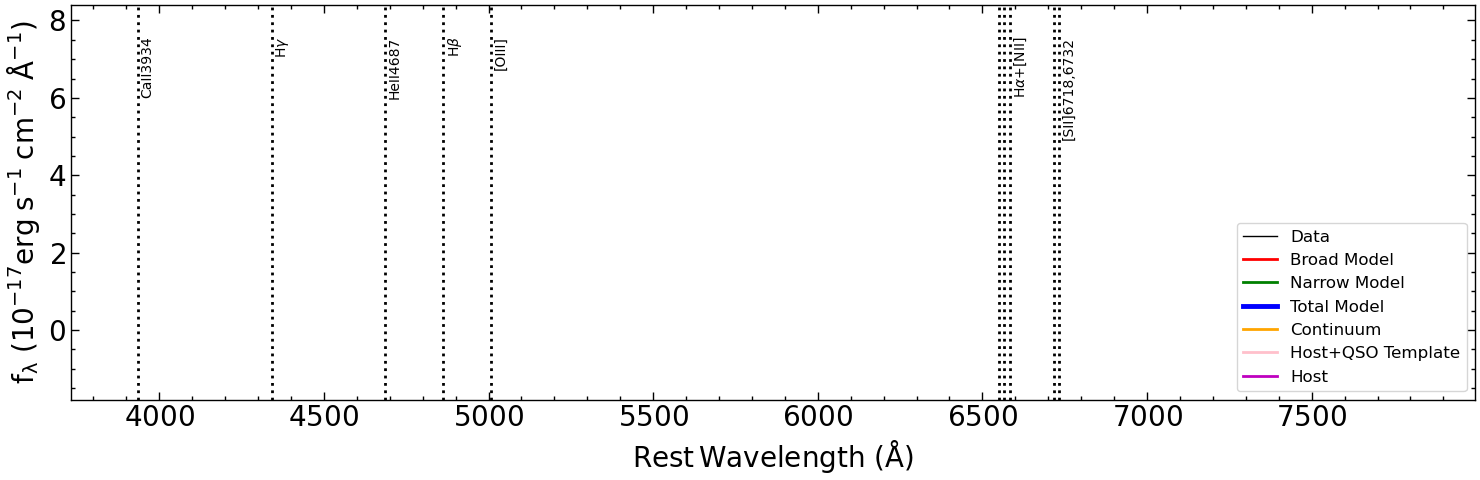

1350 ['-1.0']
1450 ['-1.0']
2200 ['-1.0']
3000 ['-1.0']
4200 ['42.41900769342412']
5100 ['42.59924565122773']
Lconti 42.59924565122773
Ha 2124.4066121595447
snr 18.578632161499375
Ha 2265.5930659881587
snr 17.742536360842507
Ha 2162.695242238469
snr 18.597666394160107
Ha 2175.0950809447454
snr 18.507667872285722
Hb 6946.474700920595
snr 1.8619969014386
Hb 7395.933340759665
snr 1.9912155154184303
Hb 7095.791113390065
snr 1.9711806099518099
Hb 7247.326194141256
snr 1.9066556178039447
MgII 0
snr 0
MgII 0
snr 0
MgII 0
snr 0
MgII 0
snr 0
CIV 0
snr 0
CIV 0
snr 0
CIV 0
snr 0
CIV 0
snr 0
[6.832770042719504, 6.891759454633046, 6.849006862778257, 6.854825013390943]
[]
[]
[]
MASS
ID:: 291
291 has a SDSS spectra, z = 0.10327
1350 ['-1.0']
1450 ['-1.0']
2200 ['-1.0']
3000 ['-1.0']
4200 ['43.12193632470601']
5100 ['43.340536869813775']
Lconti 43.340536869813775
Ha 1760.8234787924343
snr 0.6164781208132384
Ha 1759.8878734515959
snr 0.5269642839248792
Ha 1739.8559179409654
snr 0.3732941022486273
Ha 17

In [213]:
for i,ID in enumerate(data_agn_updated['ID']):
    flag = 0

    print('ID::', ID)

    #Test individual ID's (Comment out for normal running)
    #if ID != 47: 
    #   continue
    
    ra = data_agn_updated['ra'][i]
    dec = data_agn_updated['dec'][i]

    z = data_agn_updated['z_best'][i]

    ##### TODO: FIx table entries w/ z=-1!! ???????
    if z < 0:
        continue

    src = -1
    
    # GAMA
    if os.path.isfile('spec/GAMA/GAMA_%d.fit'%ID): 

        src = 1

        print(f'{ID} has a GAMA spectra, z = {z}')

        hdul_gama = fits.open('spec/GAMA/GAMA_%d.fit'%ID)
        header = hdul_gama[0].header
        data = hdul_gama[0].data
        flux = data[0]
        flux_err = data[1]
        mask = np.isfinite(flux) & np.isfinite(flux_err)

        w = WCS(header, naxis=1, relax=False, fix=False)

        wave = w.wcs_pix2world(np.arange(len(flux)), 0)[0]

        # FLUX CALIBR
        flux, flux_err, flag = flux_calib(ID, wave[mask], flux[mask], flux_err[mask], src)
        data_agn_BH['flag_cal'][-1] = flag
        # DO THE FITTING
        measureMBH(ID, src, z, wave[mask], flux, flux_err)
    
    # SDSS
    if os.path.isfile('spec/SDSS/sdss_%d.fits'%ID): 

        print(f'{ID} has a SDSS spectra, z = {z}')
        
        src = 6
        
        hdu = fits.open('spec/SDSS/sdss_%d.fits'%ID)
        wave = 10**hdu[1].data['loglam']
        flux = hdu[1].data['flux']
        flux_err = 1/np.sqrt(hdu[1].data['ivar'])
        mask = np.isfinite(flux) & np.isfinite(flux_err)

        # FLUX CALIBR
        flux, flux_err, flag = flux_calib(ID, wave[mask], flux[mask], flux_err[mask], src)
        data_agn_BH['flag_cal'][-1] = flag
        # DO THE FITTING
        measureMBH(ID, src, z, wave[mask], flux, flux_err)


    # DESI
    if os.path.isfile('spec/desi/desi_%d.txt'%ID):

        src = 7

        print(f'{ID} has a DESI spectra, z = {z}')
        
        data_spec = ascii.read('spec/desi/desi_%d.txt'%ID)

        wave = data_spec['col1']
        flux = data_spec['col2']
        flux_err = 1/np.sqrt(data_spec['col3'])

        mask = np.isfinite(flux) & np.isfinite(flux_err)
        
        # FLUX CALIBR
        flux, flux_err, flag = flux_calib(ID, wave[mask], flux[mask], flux_err[mask], src)
        data_agn_BH['flag_cal'][-1] = flag
        # DO THE FITTING
        measureMBH(ID, src, z, wave[mask], flux, flux_err)




    # OzDES _x5700

    if os.path.isfile('spec/ozdes/ozdes_%d_x5700.fits'%ID):

        src = 8

        print(f'{ID} has a x5700 spectra, z = {z}')
                
        hdul_ozdes = fits.open('spec/ozdes/ozdes_%d_x5700.fits'%ID)

        header = hdul_ozdes[0].header
        flux = hdul_ozdes[0].data
        flux_err = hdul_ozdes[1].data
        w = WCS(header, naxis=1, relax=False, fix=False)
        wave = w.wcs_pix2world(np.arange(len(flux)), 0)[0]

        print('mask')
        print(hdul_ozdes[2].data)

        mask = np.isfinite(flux) & np.isfinite(flux_err) & (hdul_ozdes[2].data==0)

        #crval1 = header['CRVAL1']
        #cdelt1 = header['CDELT1']
        #crpix1 = header['CRPIX1']

        #n_pixels = len(flux)
        #wave = crval1 + cdelt1 * (np.arange(n_pixels) + 1 - crpix1)

        # FLUX CALIBR
        flux, flux_err, flag = flux_calib(ID, wave[mask], flux[mask], flux_err[mask], src)
        data_agn_BH['flag_cal'][-1] = flag
        # DO THE FITTING
        measureMBH(ID, src, z, wave[mask], flux, flux_err)




    # OzDES _x5700_x6700

    if os.path.isfile('spec/ozdes/ozdes_%d_x5700_x6700.fits'%ID):
        
        src = 9

        print(f'{ID} has a x5700x6700 spectra, z = {z}')
                
        hdul_ozdes = fits.open('spec/ozdes/ozdes_%d_x5700_x6700.fits'%ID)

        header = hdul_ozdes[0].header
        flux = hdul_ozdes[0].data
        flux_err = hdul_ozdes[1].data
        w = WCS(header, naxis=1, relax=False, fix=False)
        wave = w.wcs_pix2world(np.arange(len(flux)), 0)[0]

        mask = np.isfinite(flux) & np.isfinite(flux_err)

        #crval1 = header['CRVAL1']
        #cdelt1 = header['CDELT1']
        #crpix1 = header['CRPIX1']

        #n_pixels = len(flux)
        #wave = crval1 + cdelt1 * (np.arange(n_pixels) + 1 - crpix1)

        # FLUX CALIBR
        flux, flux_err, flag = flux_calib(ID, wave[mask], flux[mask], flux_err[mask], src)
        data_agn_BH['flag_cal'][-1] = flag
        # DO THE FITTING
        measureMBH(ID, src, z, wave[mask], flux, flux_err)



    #OzDES _x6700

    if os.path.isfile('spec/ozdes/ozdes_%d_x6700.fits'%ID):
        
        src = 10

        print(f'{ID} has a x6700 spectra, z = {z}')
                
        hdul_ozdes = fits.open('spec/ozdes/ozdes_%d_x6700.fits'%ID)

        header = hdul_ozdes[0].header
        flux = hdul_ozdes[0].data
        flux_err = hdul_ozdes[1].data
        w = WCS(header, naxis=1, relax=False, fix=False)
        wave = w.wcs_pix2world(np.arange(len(flux)), 0)[0]

        mask = np.isfinite(flux) & np.isfinite(flux_err)

        #crval1 = header['CRVAL1']
        #cdelt1 = header['CDELT1']
        #crpix1 = header['CRPIX1']

        #n_pixels = len(flux)
        #wave = crval1 + cdelt1 * (np.arange(n_pixels) + 1 - crpix1)

        # FLUX CALIBR
        flux, flux_err, flag = flux_calib(ID, wave[mask], flux[mask], flux_err[mask], src)
        data_agn_BH['flag_cal'][-1] = flag
        # DO THE FITTING
        measureMBH(ID, src, z, wave[mask], flux, flux_err)
    
    # CDFS

    #if os.path.isfile('spec/CDFS/cdfs_%d.fits'%ID):

        #src = 11

        #print(f'{ID} has a CDFS spectra, z = {z}')

        #hdul = fits.open('spec/CDFS/cdfs_%d.fits'%ID)
        #header = hdul[0].header
        #flux = hdul[0].data
        #flux_err = TODO: add MAD
        #w = WCS(header, naxis=1, relax=False, fix=False)
        #wave = w.wcs_pix2world(np.arange(len(flux)), 0)[0]

        #mask = np.isfinite(flux) & np.isfinite(flux_err)

        # FLUX CALIBR
        #flux, flux_err, flag = flux_calib(ID, wave[mask], flux[mask], flux_err[mask], src)
        #data_agn_BH['flag_cal'][-1] = flag
        # DO THE FITTING
        #measureMBH(ID, src, z, wave[mask], flux, flux_err)

### Check if any AGN had errors while fitting

In [214]:
data_agn_BH

ID,SNR,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Ha_rv_line,M_Ha_line,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Ha_line_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
int64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
-1,-1.0,-1,0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
0,10.976084476426934,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.37061184094657,43.951536816622195,7.534240503546396,7.155315806680235,0.01093217686551808,7.534240503546396,nan,nan,-1.0,7.155315806680235,7.165585355640973,nan,nan,0.023537183022905167,nan,nan,0.01093217686551808,0.03768543927767443,nan,nan
1,5.094747882690174,6,0,2.7695025845471593,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.84760199080854,43.42852696648416,7.304922486155894,7.0220324989952685,0.09404240610885516,7.304922486155894,nan,nan,-1.0,7.0220324989952685,7.053089105413376,nan,nan,0.04151563082893698,nan,nan,0.09404240610885516,0.04925806429651937,nan,nan
2,16.75880658186577,6,0,1.8929814482144183,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.07763865395072,43.65856362962634,-1.0,6.733226798001878,0.04705737198905186,nan,nan,nan,-1.0,6.733226798001878,nan,nan,nan,nan,nan,nan,0.04705737198905186,nan,nan,nan
3,20.878929260469953,6,0,23.370267862534778,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.24770407112543,43.828629046801055,-1.0,-1.0,-1.0,nan,nan,nan,-1.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
4,6.451473430607042,6,0,0.7096559167383728,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.59854502319318,43.179469998868804,-1.0,-1.0,-1.0,nan,nan,nan,-1.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
5,6.4606450806937845,6,0,16.649762484504897,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.45619123728433,44.03711621295995,7.539498053493054,7.042937167707192,0.03020782005253759,7.539498053493054,nan,nan,-1.0,7.042937167707192,7.031904436989548,nan,nan,0.00017030848757084425,nan,nan,0.03020782005253759,0.009533393083447193,nan,nan
6,10.719517136114222,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.50842801718405,44.08935299285967,7.565871576269849,7.164430170800836,0.001437325805821,7.565871576269849,nan,nan,-1.0,7.164430170800836,7.252691656304725,nan,nan,0.00012807875543980414,nan,nan,0.001437325805821,0.007925307100672139,nan,nan
7,18.133286707692324,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.51473577504859,44.095660750724214,-1.0,-1.0,-1.0,nan,nan,nan,-1.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


### Save the results:

In [215]:
if flux_cal:
    ascii.write(data_agn_BH, 'data_agn_BH_fluxed.dat', overwrite=True)
else:
    ascii.write(data_agn_BH, 'data_agn_BH.dat', overwrite=True)

In [216]:
#flux_cal = True

In [217]:
print(flux_cal)

False


### Read the correct file (calibrated vs non-calibrated)

In [218]:
if flux_cal:
    data_agn_BH = ascii.read('data_agn_BH_fluxed.dat')
else:
    data_agn_BH = ascii.read('data_agn_BH.dat')

In [219]:
data_agn_BH

ID,SNR,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Ha_rv_line,M_Ha_line,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Ha_line_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
int64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
-1,-1.0,-1,0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
0,10.976084476426934,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.37061184094657,43.951536816622195,7.534240503546396,7.155315806680235,0.01093217686551808,7.534240503546396,nan,nan,-1.0,7.155315806680235,7.165585355640973,nan,nan,0.023537183022905167,nan,nan,0.01093217686551808,0.03768543927767443,nan,nan
1,5.094747882690174,6,0,2.7695025845471593,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.84760199080854,43.42852696648416,7.304922486155894,7.0220324989952685,0.09404240610885516,7.304922486155894,nan,nan,-1.0,7.0220324989952685,7.053089105413376,nan,nan,0.04151563082893698,nan,nan,0.09404240610885516,0.04925806429651937,nan,nan
2,16.75880658186577,6,0,1.8929814482144183,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.07763865395072,43.65856362962634,-1.0,6.733226798001878,0.04705737198905186,nan,nan,nan,-1.0,6.733226798001878,nan,nan,nan,nan,nan,nan,0.04705737198905186,nan,nan,nan
3,20.878929260469953,6,0,23.370267862534778,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.24770407112543,43.828629046801055,-1.0,-1.0,-1.0,nan,nan,nan,-1.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
4,6.451473430607042,6,0,0.7096559167383728,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.59854502319318,43.179469998868804,-1.0,-1.0,-1.0,nan,nan,nan,-1.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
5,6.4606450806937845,6,0,16.649762484504897,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.45619123728433,44.03711621295995,7.539498053493054,7.042937167707192,0.03020782005253759,7.539498053493054,nan,nan,-1.0,7.042937167707192,7.031904436989548,nan,nan,0.00017030848757084425,nan,nan,0.03020782005253759,0.009533393083447193,nan,nan
6,10.719517136114222,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.50842801718405,44.08935299285967,7.565871576269849,7.164430170800836,0.001437325805821,7.565871576269849,nan,nan,-1.0,7.164430170800836,7.252691656304725,nan,nan,0.00012807875543980414,nan,nan,0.001437325805821,0.007925307100672139,nan,nan
7,18.133286707692324,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.51473577504859,44.095660750724214,-1.0,-1.0,-1.0,nan,nan,nan,-1.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


In [220]:
# Only keep those with good flux calibration
#data_agn_BH_cal = data_agn_BH[data_agn_BH['flag_cal']==1]
data_agn_BH_cal = data_agn_BH

# First, keep the spectra with at least one valid BH mass
# Keep best SNR spectrum
data_agn_BH_tmp = data_agn_BH_cal[(data_agn_BH_cal['M']>0) | (data_agn_BH_cal['M_line']>0)].to_pandas()
#data_agn_BH_tmp = data_agn_BH_cal.to_pandas()
data_agn_BH_tmp = data_agn_BH_tmp.loc[data_agn_BH_tmp.groupby('ID')['SNR'].idxmax()]
data_agn_BH_best = table.Table.from_pandas(data_agn_BH_tmp)
data_agn_BH_best

ID,SNR,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Ha_rv_line,M_Ha_line,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Ha_line_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
int64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
0,10.976084476426934,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.37061184094657,43.951536816622195,7.534240503546396,7.155315806680235,0.01093217686551808,7.534240503546396,--,--,-1.0,7.155315806680235,7.165585355640973,--,--,0.023537183022905167,--,--,0.01093217686551808,0.03768543927767443,--,--
1,5.094747882690174,6,0,2.7695025845471593,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.84760199080854,43.42852696648416,7.304922486155894,7.0220324989952685,0.09404240610885516,7.304922486155894,--,--,-1.0,7.0220324989952685,7.053089105413376,--,--,0.04151563082893698,--,--,0.09404240610885516,0.04925806429651937,--,--
2,16.75880658186577,6,0,1.8929814482144183,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.07763865395072,43.65856362962634,-1.0,6.733226798001878,0.04705737198905186,--,--,--,-1.0,6.733226798001878,--,--,--,--,--,--,0.04705737198905186,--,--,--
5,6.4606450806937845,6,0,16.649762484504897,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.45619123728433,44.03711621295995,7.539498053493054,7.042937167707192,0.03020782005253759,7.539498053493054,--,--,-1.0,7.042937167707192,7.031904436989548,--,--,0.00017030848757084425,--,--,0.03020782005253759,0.009533393083447193,--,--
6,10.719517136114222,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.50842801718405,44.08935299285967,7.565871576269849,7.164430170800836,0.001437325805821,7.565871576269849,--,--,-1.0,7.164430170800836,7.252691656304725,--,--,0.00012807875543980414,--,--,0.001437325805821,0.007925307100672139,--,--
11,15.910138551963588,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.47464220924847,44.055567184924094,7.548920307702284,7.074609627714517,0.0031000137696172744,7.548920307702284,--,--,-1.0,7.074609627714517,7.04388456195778,--,--,6.546984716751005e-05,--,--,0.0031000137696172744,0.011454915392158217,--,--
14,20.10632246629178,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.52223945029672,44.103164425972345,7.572496631353243,7.046889498224061,0.0036859191222464102,7.572496631353243,--,--,-1.0,7.046889498224061,7.041123842891892,--,--,2.842213147067863e-05,--,--,0.0036859191222464102,0.005752608056773753,--,--
15,16.419756054702816,6,0,2.5963540203828637,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.98484746279073,43.565772438466354,8.085912591027311,7.703480683945839,0.012438397088324877,8.085912591027311,--,--,-1.0,7.703480683945839,7.823773095540659,--,--,0.018400240335871745,--,--,0.012438397088324877,0.022256062255088173,--,--
16,13.328425279983515,6,0,0.2961107735989548,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.57413998411856,43.15506495979418,7.232451141470717,7.397455526550638,0.21072659445795153,7.232451141470717,--,--,-1.0,7.397455526550638,7.156866588337619,--,--,0.06934342437065182,--,--,0.21072659445795153,0.065672264081357,--,--


In [221]:
data_agn_BH[(data_agn_BH['ID']==290)]

ID,SNR,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Ha_rv_line,M_Ha_line,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Ha_line_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
int64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
290,22.436553415429085,6,0,1.2773572651655027,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.59924565122773,43.180170626903355,-1.0,6.8519159380846,0.021586446429942324,nan,nan,nan,-1.0,6.8519159380846,nan,nan,nan,nan,nan,nan,0.021586446429942324,nan,nan,nan


### Analyze

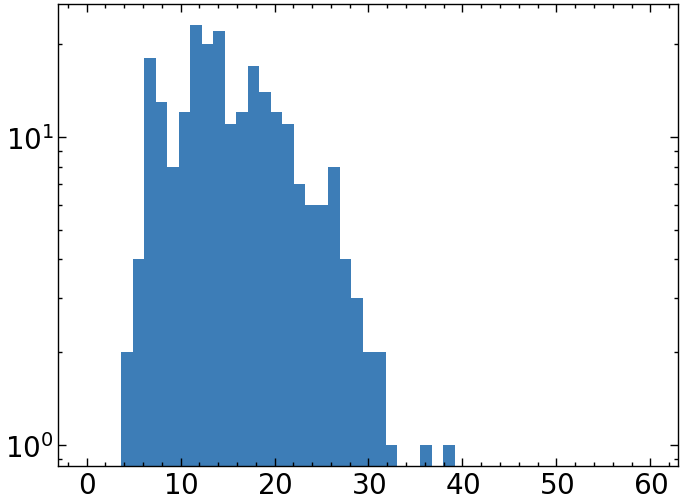

In [222]:

plt.hist(data_agn_BH['SNR'], label='3000', alpha=0.8, bins=np.linspace(0, 60), log=True);

In [223]:
#data_agn_BH['SNR']

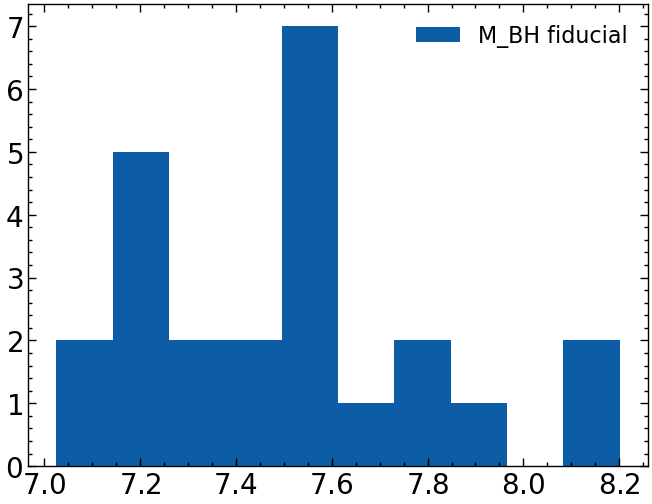

In [224]:
plt.hist(data_agn_BH_best['M'][data_agn_BH_best['M']>0], label='M_BH fiducial')
plt.legend()

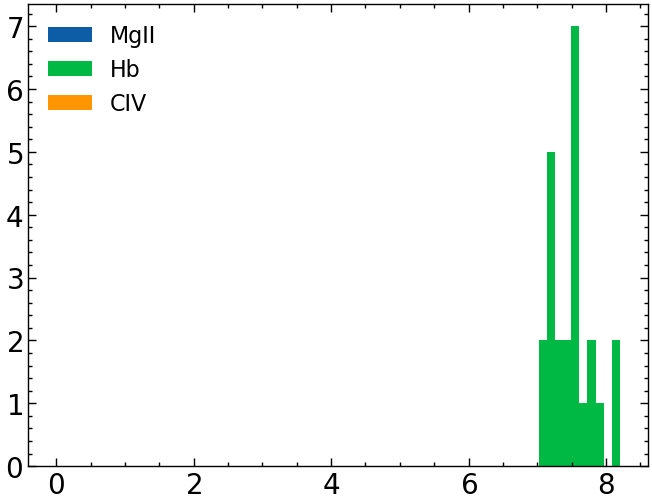

In [225]:
plt.hist(data_agn_BH['M_MgII'][data_agn_BH['M_MgII']>0], label='MgII')
plt.hist(data_agn_BH['M_Hb'][data_agn_BH['M_Hb']>0], label='Hb')
plt.hist(data_agn_BH['M_CIV'][data_agn_BH['M_CIV']>0], label='CIV')
plt.legend()

### Host Mass relation

#### Important: I changed all `z` to `z_best` 

#### Important: From here on out, use flux-calibrated file for best results

In [226]:
data_sed = ascii.read('table_mass.txt')
data_sed

ID,logMs,logMs_e,SF_excess,chi2
int64,float64,float64,float64,float64
0,10.21,0.08,10.0,2.2
1,9.44,0.13,10.0,1.2
2,10.11,0.07,10.0,1.6
3,9.97,0.02,10.0,4.1
4,9.7,0.05,10.0,2.6
5,9.67,0.18,10.0,13.9
6,9.95,0.04,10.0,1.0
7,10.04,0.1,10.0,1.3
8,10.07,0.04,10.0,3.0


In [227]:
data_agn_BH_best

ID,SNR,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Ha_rv_line,M_Ha_line,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Ha_line_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
int64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
0,10.976084476426934,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.37061184094657,43.951536816622195,7.534240503546396,7.155315806680235,0.01093217686551808,7.534240503546396,--,--,-1.0,7.155315806680235,7.165585355640973,--,--,0.023537183022905167,--,--,0.01093217686551808,0.03768543927767443,--,--
1,5.094747882690174,6,0,2.7695025845471593,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.84760199080854,43.42852696648416,7.304922486155894,7.0220324989952685,0.09404240610885516,7.304922486155894,--,--,-1.0,7.0220324989952685,7.053089105413376,--,--,0.04151563082893698,--,--,0.09404240610885516,0.04925806429651937,--,--
2,16.75880658186577,6,0,1.8929814482144183,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.07763865395072,43.65856362962634,-1.0,6.733226798001878,0.04705737198905186,--,--,--,-1.0,6.733226798001878,--,--,--,--,--,--,0.04705737198905186,--,--,--
5,6.4606450806937845,6,0,16.649762484504897,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.45619123728433,44.03711621295995,7.539498053493054,7.042937167707192,0.03020782005253759,7.539498053493054,--,--,-1.0,7.042937167707192,7.031904436989548,--,--,0.00017030848757084425,--,--,0.03020782005253759,0.009533393083447193,--,--
6,10.719517136114222,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.50842801718405,44.08935299285967,7.565871576269849,7.164430170800836,0.001437325805821,7.565871576269849,--,--,-1.0,7.164430170800836,7.252691656304725,--,--,0.00012807875543980414,--,--,0.001437325805821,0.007925307100672139,--,--
11,15.910138551963588,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.47464220924847,44.055567184924094,7.548920307702284,7.074609627714517,0.0031000137696172744,7.548920307702284,--,--,-1.0,7.074609627714517,7.04388456195778,--,--,6.546984716751005e-05,--,--,0.0031000137696172744,0.011454915392158217,--,--
14,20.10632246629178,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.52223945029672,44.103164425972345,7.572496631353243,7.046889498224061,0.0036859191222464102,7.572496631353243,--,--,-1.0,7.046889498224061,7.041123842891892,--,--,2.842213147067863e-05,--,--,0.0036859191222464102,0.005752608056773753,--,--
15,16.419756054702816,6,0,2.5963540203828637,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.98484746279073,43.565772438466354,8.085912591027311,7.703480683945839,0.012438397088324877,8.085912591027311,--,--,-1.0,7.703480683945839,7.823773095540659,--,--,0.018400240335871745,--,--,0.012438397088324877,0.022256062255088173,--,--
16,13.328425279983515,6,0,0.2961107735989548,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.57413998411856,43.15506495979418,7.232451141470717,7.397455526550638,0.21072659445795153,7.232451141470717,--,--,-1.0,7.397455526550638,7.156866588337619,--,--,0.06934342437065182,--,--,0.21072659445795153,0.065672264081357,--,--


In [228]:
data_agn_updated

ra,dec,z,logMs,ID,id,RA,DEC,z_simb,r_z_simb,z_best,err_reason
float64,float64,float64,float64,int64,int64,float64,float64,float64,str19,float64,bool
0.47615,0.125693,0.1395,9.885926339801431,0,0,0.47615,0.125693,0.13954,2015ApJS..219...12A,0.13954,False
2.36003,0.325606,0.1138,9.468347330412158,1,1,2.36003,0.325606,-1.0,--,0.1138,False
4.27033,-0.493348,0.0672,9.970811610872518,2,2,4.27033,-0.493348,0.06716,2012ApJS..203...21A,0.06716,False
6.96605,0.794382,0.0821,9.79657433321043,3,3,6.96605,0.794382,0.08207,2012ApJS..203...21A,0.08207,False
8.39416,0.048925,0.1067,9.90471554527868,4,4,8.39416,0.048925,0.10677,2009ApJS..182..543A,0.10677,False
8.15918,-1.009817,0.0917,9.961421094066448,5,5,8.15918,-1.009817,0.09172,2012ApJS..203...21A,0.09172,False
11.38946,-0.969121,0.1376,9.869231719730976,6,6,11.38946,-0.969121,0.1376,2012ApJS..203...21A,0.1376,False
11.51401,0.636591,0.1246,9.58092497567562,7,7,11.51401,0.636591,-1.0,--,0.1246,False
14.01926,0.59255,0.056,9.889861721258189,8,8,14.01926,0.59255,0.056,2023ApJS..267...17L,0.056,False


In [229]:
data_sed

ID,logMs,logMs_e,SF_excess,chi2
int64,float64,float64,float64,float64
0,10.21,0.08,10.0,2.2
1,9.44,0.13,10.0,1.2
2,10.11,0.07,10.0,1.6
3,9.97,0.02,10.0,4.1
4,9.7,0.05,10.0,2.6
5,9.67,0.18,10.0,13.9
6,9.95,0.04,10.0,1.0
7,10.04,0.1,10.0,1.3
8,10.07,0.04,10.0,3.0


In [230]:
table.join(data_sed, data_agn_BH_best, keys='ID')

ID,logMs,logMs_e,SF_excess,chi2,SNR,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Ha_rv_line,M_Ha_line,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Ha_line_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
int64,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
0,10.21,0.08,10.0,2.2,10.976084476426934,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.37061184094657,43.951536816622195,7.534240503546396,7.155315806680235,0.01093217686551808,7.534240503546396,--,--,-1.0,7.155315806680235,7.165585355640973,--,--,0.023537183022905167,--,--,0.01093217686551808,0.03768543927767443,--,--
1,9.44,0.13,10.0,1.2,5.094747882690174,6,0,2.7695025845471593,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.84760199080854,43.42852696648416,7.304922486155894,7.0220324989952685,0.09404240610885516,7.304922486155894,--,--,-1.0,7.0220324989952685,7.053089105413376,--,--,0.04151563082893698,--,--,0.09404240610885516,0.04925806429651937,--,--
2,10.11,0.07,10.0,1.6,16.75880658186577,6,0,1.8929814482144183,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.07763865395072,43.65856362962634,-1.0,6.733226798001878,0.04705737198905186,--,--,--,-1.0,6.733226798001878,--,--,--,--,--,--,0.04705737198905186,--,--,--
5,9.67,0.18,10.0,13.9,6.4606450806937845,6,0,16.649762484504897,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.45619123728433,44.03711621295995,7.539498053493054,7.042937167707192,0.03020782005253759,7.539498053493054,--,--,-1.0,7.042937167707192,7.031904436989548,--,--,0.00017030848757084425,--,--,0.03020782005253759,0.009533393083447193,--,--
6,9.95,0.04,10.0,1.0,10.719517136114222,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.50842801718405,44.08935299285967,7.565871576269849,7.164430170800836,0.001437325805821,7.565871576269849,--,--,-1.0,7.164430170800836,7.252691656304725,--,--,0.00012807875543980414,--,--,0.001437325805821,0.007925307100672139,--,--
11,10.34,0.09,10.0,1.5,15.910138551963588,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.47464220924847,44.055567184924094,7.548920307702284,7.074609627714517,0.0031000137696172744,7.548920307702284,--,--,-1.0,7.074609627714517,7.04388456195778,--,--,6.546984716751005e-05,--,--,0.0031000137696172744,0.011454915392158217,--,--
14,10.13,0.06,10.0,2.5,20.10632246629178,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.52223945029672,44.103164425972345,7.572496631353243,7.046889498224061,0.0036859191222464102,7.572496631353243,--,--,-1.0,7.046889498224061,7.041123842891892,--,--,2.842213147067863e-05,--,--,0.0036859191222464102,0.005752608056773753,--,--
15,10.08,0.05,10.0,0.8,16.419756054702816,6,0,2.5963540203828637,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.98484746279073,43.565772438466354,8.085912591027311,7.703480683945839,0.012438397088324877,8.085912591027311,--,--,-1.0,7.703480683945839,7.823773095540659,--,--,0.018400240335871745,--,--,0.012438397088324877,0.022256062255088173,--,--
16,10.13,0.06,10.0,1.1,13.328425279983515,6,0,0.2961107735989548,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.57413998411856,43.15506495979418,7.232451141470717,7.397455526550638,0.21072659445795153,7.232451141470717,--,--,-1.0,7.397455526550638,7.156866588337619,--,--,0.06934342437065182,--,--,0.21072659445795153,0.065672264081357,--,--


In [231]:
data_agn_updated

ra,dec,z,logMs,ID,id,RA,DEC,z_simb,r_z_simb,z_best,err_reason
float64,float64,float64,float64,int64,int64,float64,float64,float64,str19,float64,bool
0.47615,0.125693,0.1395,9.885926339801431,0,0,0.47615,0.125693,0.13954,2015ApJS..219...12A,0.13954,False
2.36003,0.325606,0.1138,9.468347330412158,1,1,2.36003,0.325606,-1.0,--,0.1138,False
4.27033,-0.493348,0.0672,9.970811610872518,2,2,4.27033,-0.493348,0.06716,2012ApJS..203...21A,0.06716,False
6.96605,0.794382,0.0821,9.79657433321043,3,3,6.96605,0.794382,0.08207,2012ApJS..203...21A,0.08207,False
8.39416,0.048925,0.1067,9.90471554527868,4,4,8.39416,0.048925,0.10677,2009ApJS..182..543A,0.10677,False
8.15918,-1.009817,0.0917,9.961421094066448,5,5,8.15918,-1.009817,0.09172,2012ApJS..203...21A,0.09172,False
11.38946,-0.969121,0.1376,9.869231719730976,6,6,11.38946,-0.969121,0.1376,2012ApJS..203...21A,0.1376,False
11.51401,0.636591,0.1246,9.58092497567562,7,7,11.51401,0.636591,-1.0,--,0.1246,False
14.01926,0.59255,0.056,9.889861721258189,8,8,14.01926,0.59255,0.056,2023ApJS..267...17L,0.056,False


In [232]:
plt.scatter(data_join['logMBH'], data_join['M_line'])
plt.scatter(data_join['logMBH'], data_join['M_Ha_rv_line'])

x = np.linspace(5, 9)
plt.plot(x, x)

plt.plot(x, x+.2)

KeyError: 'logMBH'

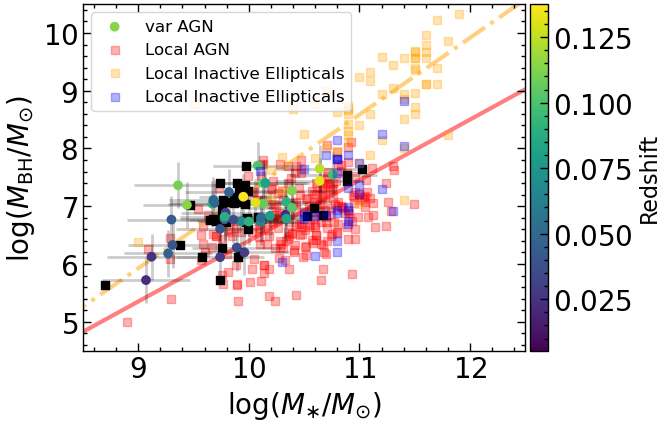

In [244]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

# DES AGN
data_sed = ascii.read('table_mass.txt')
data_sed['logMs_cigale'] = data_sed['logMs'] 
data_join = table.join(data_sed, data_agn_BH_best, keys='ID')
data_join = table.join(data_agn_updated, data_join, keys='ID')

#data_join = table.join(data_agn_updated, data_agn_BH_best, keys='ID')


cat_join = SkyCoord(data_join['ra'], data_join['dec'], unit='deg')
#mask_chi2 = (data_join['SF_excess'] > 1.2) & (data_join['chi2'] < 5) # This selects against very luminous AGNs / high BHs or non SF galaxies
mask_chi2 = data_join['ID'] > 0

# Local AGN
data_sed_local = ascii.read('../rv15.txt')

# Local Inactive Ellipticals
data_sed_elliptical = ascii.read('../elliptical_agn.txt')

condition = data_sed_elliptical['$M_*$']=='\\nodata'
rows_to_delete = np.where(condition)[0]
data_sed_elliptical.remove_rows(rows_to_delete)

data_sed_elliptical['$M_*$'] = data_sed_elliptical['$M_*$'].astype(float)

mask_elliptical = (data_sed_elliptical['HT']=='E')
mask_spiral = (data_sed_elliptical['HT']=='S')


fig, ax = plt.subplots(1,1, figsize=(6, 4.5))

#
x = np.logspace(8, 13)
ax.plot(np.log10(x), 7.45 + 1.05*np.log10(x/1e11), lw=3, 
        #label='local AGN',
        alpha = 0.5,
        color='red', zorder=-1)
ax.plot(np.log10(x), 7.89 + 1.33*np.log10(x/3e10), lw=3, 
        #label='local inactive\nellipticals', 
        alpha = 0.5,
        linestyle='dashdot', color='orange', zorder=-1)


# _cigale
# DES AGN
im = ax.scatter(data_join['logMs_cigale'][mask_chi2], data_join['M_line'][mask_chi2], c=data_join['z'][mask_chi2],
                label = 'var AGN', marker='o')

ax.errorbar(data_join['logMs_cigale'][mask_chi2], data_join['M_line'][mask_chi2], c='k', zorder=-1,
                 xerr=0.4, yerr=0.4, marker=None, linestyle='none', alpha=0.2)

ax.scatter(data_join['logMs_1'][mask_chi2], data_join['M_line'][mask_chi2], c='k', zorder=-1,
                marker='s')

# Local AGN
ax.scatter(data_sed_local['logM*'], data_sed_local['logMBH'], marker='s', alpha = 0.3, label = 'Local AGN', color = 'red', zorder=-10)


# Local Inactive Ellipticals
### TODO: it looks like this data isn't in log, or its in different units, bc it isn't showing up in the plot
ax.scatter(data_sed_elliptical['$M_*$'][mask_elliptical], np.log10(data_sed_elliptical['$M_{\\rm BH}$'][mask_elliptical]), marker='s', color = 'orange', alpha = 0.3, label = 'Local Inactive Ellipticals')
ax.scatter(data_sed_elliptical['$M_*$'][mask_spiral], np.log10(data_sed_elliptical['$M_{\\rm BH}$'][mask_spiral]), marker='s', color = 'blue', alpha = 0.3, label = 'Local Inactive Ellipticals')


#ax.errorbar(data_join_des['logMs'][mask_chi2], data_join_des['M_CIV'][mask_chi2], yerr=0.4, xerr=0.4,  marker='o', linestyle='none', label='CIV')
#ax.errorbar(data_join_des['logMs'][mask_chi2], data_join_des['M_Hb'][mask_chi2], yerr=0.4, xerr=0.4,  marker='o', linestyle='none', label='Hb')
ax.legend(fontsize=12, frameon=True)

divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='4%', pad=0.05)
fig.colorbar(im, cax=cax)
cax.set_ylabel(r'Redshift')

ax.set_xlim(8.5, 12.5)
ax.set_ylim(4.5, 10.5)

ax.set_ylabel(r'$\log(M_{\rm{BH}} / M_{\odot})$', fontsize=20)
ax.set_xlabel(r'$\log(M_{\ast} / M_{\odot})$', fontsize=20)

#fig.tight_layout()
fig.savefig('hostrel.pdf', dpi=300)


# Color by redshift
# Check with Jennifers paper
# Seems consistent with Fabio's result https://arxiv.org/pdf/2308.12331.pdf



In [4]:
import numpy as np
np.array([2, 2]).T * np.array([2, 1]) 

[m n]T [m n] = [mm, nn]

array([4, 2])

In [234]:
data_sed = ascii.read('table_mass.txt')
data_sed['logMs_cigale'] = data_sed['logMs'] 
data_join = table.join(data_sed, data_agn_BH_best, keys='ID')
data_join = table.join(data_agn_updated, data_join, keys='ID')


In [235]:
data_join

ra,dec,z,logMs_1,ID,id,RA,DEC,z_simb,r_z_simb,z_best,err_reason,logMs_2,logMs_e,SF_excess,chi2,logMs_cigale,SNR,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Ha_rv_line,M_Ha_line,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Ha_line_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
float64,float64,float64,float64,int64,int64,float64,float64,float64,str19,float64,bool,float64,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
0.47615,0.125693,0.1395,9.885926339801431,0,0,0.47615,0.125693,0.13954,2015ApJS..219...12A,0.13954,False,10.21,0.08,10.0,2.2,10.21,10.976084476426934,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.37061184094657,43.951536816622195,7.534240503546396,7.155315806680235,0.01093217686551808,7.534240503546396,--,--,-1.0,7.155315806680235,7.165585355640973,--,--,0.023537183022905167,--,--,0.01093217686551808,0.03768543927767443,--,--
2.36003,0.325606,0.1138,9.468347330412158,1,1,2.36003,0.325606,-1.0,--,0.1138,False,9.44,0.13,10.0,1.2,9.44,5.094747882690174,6,0,2.7695025845471593,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.84760199080854,43.42852696648416,7.304922486155894,7.0220324989952685,0.09404240610885516,7.304922486155894,--,--,-1.0,7.0220324989952685,7.053089105413376,--,--,0.04151563082893698,--,--,0.09404240610885516,0.04925806429651937,--,--
4.27033,-0.493348,0.0672,9.970811610872518,2,2,4.27033,-0.493348,0.06716,2012ApJS..203...21A,0.06716,False,10.11,0.07,10.0,1.6,10.11,16.75880658186577,6,0,1.8929814482144183,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.07763865395072,43.65856362962634,-1.0,6.733226798001878,0.04705737198905186,--,--,--,-1.0,6.733226798001878,--,--,--,--,--,--,0.04705737198905186,--,--,--
8.15918,-1.009817,0.0917,9.961421094066448,5,5,8.15918,-1.009817,0.09172,2012ApJS..203...21A,0.09172,False,9.67,0.18,10.0,13.9,9.67,6.4606450806937845,6,0,16.649762484504897,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.45619123728433,44.03711621295995,7.539498053493054,7.042937167707192,0.03020782005253759,7.539498053493054,--,--,-1.0,7.042937167707192,7.031904436989548,--,--,0.00017030848757084425,--,--,0.03020782005253759,0.009533393083447193,--,--
11.38946,-0.969121,0.1376,9.869231719730976,6,6,11.38946,-0.969121,0.1376,2012ApJS..203...21A,0.1376,False,9.95,0.04,10.0,1.0,9.95,10.719517136114222,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.50842801718405,44.08935299285967,7.565871576269849,7.164430170800836,0.001437325805821,7.565871576269849,--,--,-1.0,7.164430170800836,7.252691656304725,--,--,0.00012807875543980414,--,--,0.001437325805821,0.007925307100672139,--,--
19.87115,-0.144376,0.0901,9.898176483497677,11,11,19.87115,-0.144376,0.09009,2012ApJS..203...21A,0.09009,False,10.34,0.09,10.0,1.5,10.34,15.910138551963588,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.47464220924847,44.055567184924094,7.548920307702284,7.074609627714517,0.0031000137696172744,7.548920307702284,--,--,-1.0,7.074609627714517,7.04388456195778,--,--,6.546984716751005e-05,--,--,0.0031000137696172744,0.011454915392158217,--,--
36.53416,-0.88856,0.1065,9.754348335711018,14,14,36.53416,-0.88856,0.10647,2012ApJS..203...21A,0.10647,False,10.13,0.06,10.0,2.5,10.13,20.10632246629178,6,0,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.52223945029672,44.103164425972345,7.572496631353243,7.046889498224061,0.0036859191222464102,7.572496631353243,--,--,-1.0,7.046889498224061,7.041123842891892,--,--,2.842213147067863e-05,--,--,0.0036859191222464102,0.005752608056773753,--,--
44.96551,-0.25634,0.1014,9.9731278535997,15,15,44.96551,-0.25634,0.10169,2009ApJS..182..543A,0.10169,False,10.08,0.05,10.0,0.8,10.08,16.419756054702816,6,0,2.5963540203828637,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.98484746279073,43.565772438466354,8.085912591027311,7.703480683945839,0.012438397088324877,8.085912591027311,--,--,-1.0,7.703480683945839,7.82

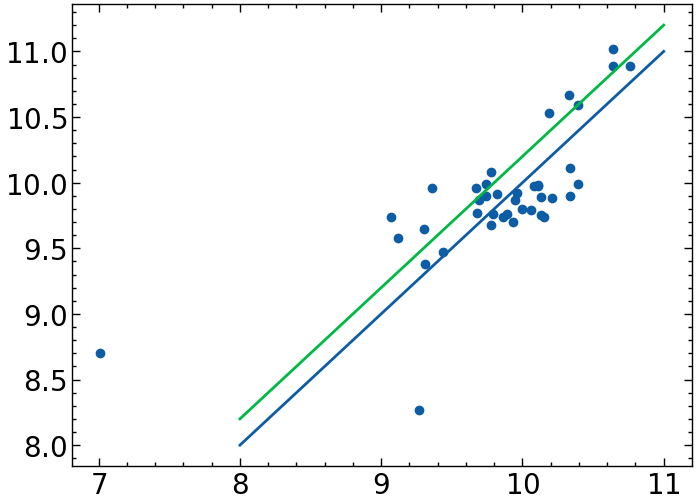

In [237]:
# NSA vs. RanbowLasso+CIGALE stellar masses
plt.scatter(data_join['logMs_cigale'], data_join['logMs_1'])

x = np.linspace(8, 11)
plt.plot(x, x)

plt.plot(x, x+.2)

In [276]:
data_join_good[data_join_good['logMs'] < 10]

Name,RA,dec,g,SNR_1,sigma_LB,lgM,dchi2,lgtau,z_ph,z_ph_plus,z_ph_minus,z_sp,z_sp source,W1-W2,lgF,Field,z_simb,r_z_simb,z_ozdes,z_desi,z_best,ID,comment,err_reason,logMs,logMs_e,SF_excess,chi2,SNR_2,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
str20,float64,float64,float64,float64,float64,str14,float64,str16,float64,float64,str4,float64,str4,float64,float64,str5,float64,str19,float64,float64,float64,int64,str150,bool,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
J003822.00-434437.71,9.5917,-43.7438,23.1,11.1,8.7,$7.4 \pm 0.6$,0.0,$2.4 \pm 0.6$,0.35,0.03,0.04,nan,None,0.9,nan,SN-E2,-1.0,--,-1.0,-1.0,0.35,374,--,False,9.7,0.1,1.6,2.5,0.6785110496303762,8,1,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,42.643760280559114,43.224685256234736,6.8099271756043,7.325267426387795,--,--,6.8099271756043,--,--,7.325267426387795,--,--,--,--,--,--,--


In [277]:
data_join_des[mask_chi2][(data_join_des['M_line'][mask_chi2] > 6) & (data_join_des['z_best'][mask_chi2] < 1)]

Name,RA,dec,g,SNR_1,sigma_LB,lgM,dchi2,lgtau,z_ph,z_ph_plus,z_ph_minus,z_sp,z_sp source,W1-W2,lgF,Field,z_simb,r_z_simb,z_ozdes,z_desi,z_best,ID,comment,err_reason,logMs,logMs_e,SF_excess,chi2,SNR_2,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
str20,float64,float64,float64,float64,float64,str14,float64,str16,float64,float64,str4,float64,str4,float64,float64,str5,float64,str19,float64,float64,float64,int64,str150,bool,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
J032818.10-280747.81,52.0754,-28.1299,20.8,25.6,19.9,$10.2 \pm 0.6$,0.0,$3.2 \pm 0.6$,0.9,0.2,0.35,nan,None,0.7,nan,SN-C3,0.894,2017AJ....153..107T,0.8939099907875061,-1.0,0.8939099907875061,56,--,False,11.06,0.09,1.4,1.7,1.1571526681670206,8,1,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.53731159985643,45.24911882889762,8.529899797135478,8.638970736513278,0.12201882370042991,--,8.529899797135478,--,--,8.638970736513278,--,--,0.09458553573369463,--,--,0.12201882370042991,--
J032718.71-281857.94,51.828,-28.3161,18.9,25.6,19.8,$10.2 \pm 0.1$,2.3,$2.6 \pm 0.8$,0.65,0.1,0.20,nan,None,0.9,nan,SN-C3,0.634,2017AJ....153..107T,0.6335499882698059,-1.0,0.6335499882698059,66,--,False,10.38,0.12,1.5,0.9,50.08060057944602,8,1,60.356609712825836,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.756875581599054,45.337800557274676,8.449331629206686,8.331508844301815,0.04676003317127717,8.449331629206686,8.264544273335858,--,8.331508844301815,8.068766034365103,--,0.04509084226371215,0.00015276406500887922,--,0.04676003317127717,0.00011963268715498697,--
J033203.75-285245.97,53.0156,-28.8794,21.5,22.2,18.4,$9.9 \pm 0.6$,0.0,$2.4 \pm 0.8$,0.9,0.25,0.05,0.77,2dF,0.8,nan,SN-C3,0.768,2017AJ....153..107T,0.7706400156021118,-1.0,0.7706400156021118,115,--,False,10.5,0.23,1.3,0.8,4.434518998162349,8,1,3.028580476220455,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.91157545916147,44.62338268820266,7.767274100031919,7.4987402723472165,0.00658729454902406,7.767274100031919,--,--,7.4987402723472165,--,--,0.00012840779781601812,--,--,0.00658729454902406,--,--
J033320.02-275912.63,53.3334,-27.9868,21.5,22.1,18.4,$9.9 \pm 0.4$,0.0,$1.8 \pm 0.2$,0.65,0.4,0.30,0.6833,ACES,0.7,nan,SN-C3,0.683,2010ApJS..191..124S,-1.0,-1.0,0.683,130,--,False,10.27,0.17,1.3,0.8,8.271622393661357,2,1,2.4947383820193627,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.15601528301209,44.86782251205328,8.91238153709622,8.495341975938977,0.11743203829169424,--,8.91238153709622,--,--,8.495341975938977,--,--,0.09662253531958873,--,--,0.11743203829169424,--
J033137.70-284808.11,52.9071,-28.8023,21.4,25.1,19.5,$9.8 \pm 0.6$,0.1,$2.5 \pm 0.6$,0.85,0.15,0.30,nan,None,0.9,nan,SN-C3,0.862,2017AJ....153..107T,0.8616700172424316,-1.0,0.8616700172424316,167,--,False,10.82,0.22,1.3,1.5,7.557295246444445,8,1,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.15514801535058,44.866955244391775,7.95171849240923,8.006965853611444,0.0051053583577974435,--,7.95171849240923,--,--,8.006965853611444,--,--,0.0050015805775548644,--,--,0.0051053583577974435,--
J033310.00-282754.18,53.2917,-28.465,21.1,23.8,19.0,$9.7 \pm 0.5$,0.1,$1.8 \pm 0.2$,0.7,0.35,0.35,nan,None,0.8,nan,SN-C3,-1.0,--,0.6931099891662598,-1.0,0.6931099891662598,172,--,False,10.29,0.12,1.4,1.3,5.780788788731524,8,1,3.805118898409462,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.95098659296713,44.531911568642755,7.761813060560374,7.688705848688038,0.0524218994333201,--,7.761813060560374,--,--,7.688705848688038,--,--,0.039621361944770984,--,--,0.0524218994333201,--
J032912.09-273147.23,52.3004,-27.5298,23.4,9.1,9.5,$10.7 \pm 0.3$,0.6,$2.4 \pm 0.8$,1.01,0.02,0.03,nan,None,0.4,nan,SN-C3,-1.0,--,0.9680200219154358,-1.0,0.9680200219154358,213,--,False,11.04,0.08,2.2,0.3,2.5494254384952493,8,1,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1

In [278]:
data_join_des[mask_chi2][data_join_des['M_line'][mask_chi2] > 2]

Name,RA,dec,g,SNR_1,sigma_LB,lgM,dchi2,lgtau,z_ph,z_ph_plus,z_ph_minus,z_sp,z_sp source,W1-W2,lgF,Field,z_simb,r_z_simb,z_ozdes,z_desi,z_best,ID,comment,err_reason,logMs,logMs_e,SF_excess,chi2,SNR_2,src,flag_cal,f_conti,L1350,L1450,L2200,L3000,L4200,L5100,Lconti,Lbol,M,M_line,M_line_e,M_Hb,M_MgII,M_CIV,M_Hb_line,M_MgII_line,M_CIV_line,M_Hb_e,M_MgII_e,M_CIV_e,M_Hb_line_e,M_MgII_line_e,M_CIV_line_e
str20,float64,float64,float64,float64,float64,str14,float64,str16,float64,float64,str4,float64,str4,float64,float64,str5,float64,str19,float64,float64,float64,int64,str150,bool,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
J032818.10-280747.81,52.0754,-28.1299,20.8,25.6,19.9,$10.2 \pm 0.6$,0.0,$3.2 \pm 0.6$,0.9,0.2,0.35,nan,None,0.7,nan,SN-C3,0.894,2017AJ....153..107T,0.8939099907875061,-1.0,0.8939099907875061,56,--,False,11.06,0.09,1.4,1.7,1.1571526681670206,8,1,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.53731159985643,45.24911882889762,8.529899797135478,8.638970736513278,0.12201882370042991,--,8.529899797135478,--,--,8.638970736513278,--,--,0.09458553573369463,--,--,0.12201882370042991,--
J032718.71-281857.94,51.828,-28.3161,18.9,25.6,19.8,$10.2 \pm 0.1$,2.3,$2.6 \pm 0.8$,0.65,0.1,0.20,nan,None,0.9,nan,SN-C3,0.634,2017AJ....153..107T,0.6335499882698059,-1.0,0.6335499882698059,66,--,False,10.38,0.12,1.5,0.9,50.08060057944602,8,1,60.356609712825836,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.756875581599054,45.337800557274676,8.449331629206686,8.331508844301815,0.04676003317127717,8.449331629206686,8.264544273335858,--,8.331508844301815,8.068766034365103,--,0.04509084226371215,0.00015276406500887922,--,0.04676003317127717,0.00011963268715498697,--
J033203.75-285245.97,53.0156,-28.8794,21.5,22.2,18.4,$9.9 \pm 0.6$,0.0,$2.4 \pm 0.8$,0.9,0.25,0.05,0.77,2dF,0.8,nan,SN-C3,0.768,2017AJ....153..107T,0.7706400156021118,-1.0,0.7706400156021118,115,--,False,10.5,0.23,1.3,0.8,4.434518998162349,8,1,3.028580476220455,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,43.91157545916147,44.62338268820266,7.767274100031919,7.4987402723472165,0.00658729454902406,7.767274100031919,--,--,7.4987402723472165,--,--,0.00012840779781601812,--,--,0.00658729454902406,--,--
J033320.02-275912.63,53.3334,-27.9868,21.5,22.1,18.4,$9.9 \pm 0.4$,0.0,$1.8 \pm 0.2$,0.65,0.4,0.30,0.6833,ACES,0.7,nan,SN-C3,0.683,2010ApJS..191..124S,-1.0,-1.0,0.683,130,--,False,10.27,0.17,1.3,0.8,8.271622393661357,2,1,2.4947383820193627,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.15601528301209,44.86782251205328,8.91238153709622,8.495341975938977,0.11743203829169424,--,8.91238153709622,--,--,8.495341975938977,--,--,0.09662253531958873,--,--,0.11743203829169424,--
J032831.41-285249.82,52.1309,-28.8805,20.8,24.9,19.7,$10.1 \pm 0.4$,0.2,$3.1 \pm 0.6$,1.2,0.45,0.05,nan,None,1.2,nan,SN-C3,1.05,2017AJ....153..107T,1.0495500564575195,-1.0,1.0495500564575195,149,--,False,10.89,0.17,1.3,2.5,28.245764590389868,8,1,109.31601370084053,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.58164254973438,45.293449778775575,8.198496573643034,8.258517402120194,0.005221132374236101,--,8.198496573643034,--,--,8.258517402120194,--,--,0.005284364678854506,--,--,0.005221132374236101,--
J033211.42-284324.07,53.0476,-28.7234,22.4,23.8,19.1,$10.1 \pm 0.4$,0.2,$2.8 \pm 0.7$,1.35,0.05,0.20,1.2369,2dF,0.8,nan,SN-C3,1.238,2017AJ....153..107T,1.2360299825668335,-1.0,1.2360299825668335,155,--,False,11.4,0.05,1.3,2.0,11.77035499240108,8,1,inf,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,44.36288438525427,45.07469161429546,8.869070178988073,8.83124538619007,0.006438695648440308,--,8.869070178988073,--,--,8.83124538619007,--,--,0.005911131797717159,--,--,0.006438695648440308,--
J033137.70-284808.11,52.9071,-28.8023,21.4,25.1,19.5,$9.8 \pm 0.6$,0.1,$2.5 \pm 0.6$,0.85,0.15,0.30,nan,None,0.9,nan,SN-C3,0.862,2017AJ....153..107T,0.8616700172424316,-1.0,0.8616700172424316,167,--,False,10.82,0.22,1.3,1.5,7.5572952464

In [279]:
7.45 + 1.05*np.log10(3e10/1e11)

6.900977317455646

### Changed 'i-mag' to 'g' line 10

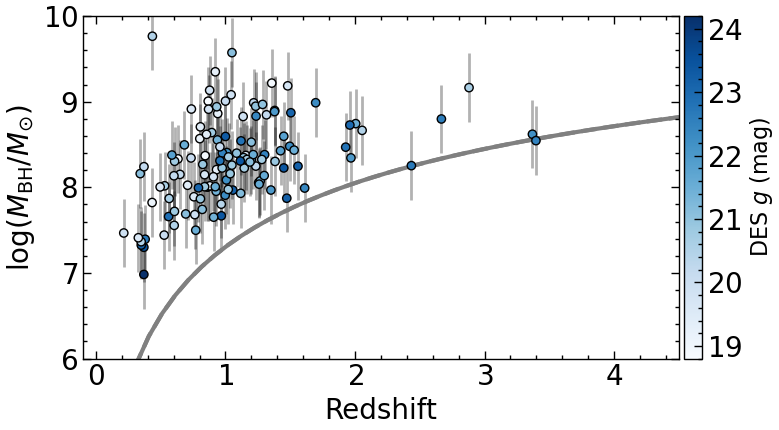

In [280]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

data_sed = ascii.read('table_mass.txt')
data_join = table.join(data_sed, data_agn_BH_best, keys='ID')
data_join = table.join(data_agn_updated, data_join, keys='ID')

fig, ax = plt.subplots(1,1, figsize=(8, 4.5))

im = ax.scatter(data_join['z_best'], data_join['M_line'],
                c=data_join['g'], cmap='Blues',
                marker='o', edgecolors='k', label='spec-z')

ax.errorbar(data_join['z_best'], data_join['M_line'],
            yerr=0.4, marker=None, linestyle='none', color='k', zorder=-1, alpha=0.3)


#ax.legend(loc=4, frameon=True)
ax.set_xlabel('Redshift', fontsize=20)
ax.set_ylabel(r'$\log(M_{\rm{BH}} / M_{\odot})$', fontsize=20)

ax.set_xlim(-.1, 4.5)
ax.set_ylim(6.0, 10)

divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='3%', pad=0.05)
fig.colorbar(im, cax=cax)
cax.set_ylabel(r'DES $g$ (mag)')

a = -4.7
b = -1.9
m5 = 24.5
gamma = 0.039
SFinf = 0.1
zs = np.linspace(0, 5)
d_pc = cosmo.luminosity_distance(zs).to(u.pc).value
alpha = 0.0 # for galaxies
K = -2.5*(1 + alpha) * np.log10(1 + zs) # K-correction
logM = 1/b*(2.5 * np.log10(SFinf * gamma**-1/2) - a - 5 * np.log10(d_pc) + 5 - K + m5 )

# BHs are much bigger compared to their hosts, so should outshine host more easily

ax.set_autoscale_on(False)
ax.plot(zs, logM, lw=3, color='gray', zorder=-1)
#ax.plot(zs, logM+0.7, lw=3, color='gray', zorder=-1)


ax.plot(zs, logM, lw=3, color='gray', zorder=-1, linestyle='dashed')


fig.tight_layout()
fig.savefig('bhmassredshift.pdf', dpi=300)

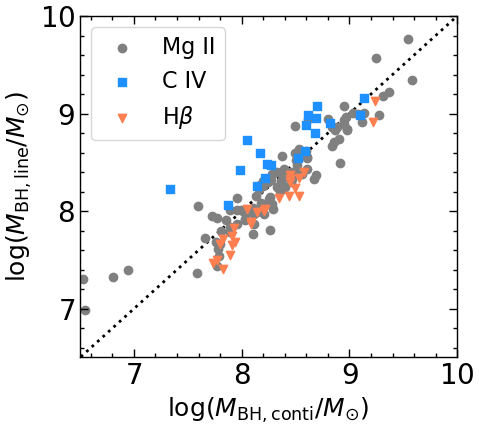

In [281]:
# TODO: Line SNR > 2

fig, ax = plt.subplots(1,1, figsize=(5, 4.5))

#
x = np.logspace(5, 13)
ax.plot(np.log10(x), np.log10(x/1) , linestyle='dotted', color='k', zorder=-1)

mask_f = data_join['f_conti'] > -100
ax.scatter(data_join['M_MgII'][mask_f], data_join['M_MgII_line'][mask_f], label='Mg II', color='gray', marker='o')
ax.scatter(data_join['M_CIV'][mask_f], data_join['M_CIV_line'][mask_f], label='C IV', color='dodgerblue', marker='s')
ax.scatter(data_join['M_Hb'][mask_f], data_join['M_Hb_line'][mask_f], label=r'H$\beta$', color='coral', marker='v')

#ax.scatter(data_join['M_MgII'][~mask_f], data_join['M_MgII_line'][~mask_f], label='Mg II', color='gray', edgecolor='k', marker='o')
#ax.scatter(data_join['M_CIV'][~mask_f], data_join['M_CIV_line'][~mask_f], label='C IV', color='dodgerblue', edgecolor='k', marker='s')
#ax.scatter(data_join['M_Hb'][~mask_f], data_join['M_Hb_line'][~mask_f], label=r'H$\beta$', color='coral', edgecolor='k', marker='v')

ax.legend(frameon=True)
ax.set_xlim(6.5, 10)
ax.set_ylim(6.5, 10)

ax.set_xlabel(r'$\log(M_{\rm{BH}, conti} / M_{\odot})$', fontsize=18)
ax.set_ylabel(r'$\log(M_{\rm{BH}, line} / M_{\odot})$', fontsize=18)

fig.tight_layout()
fig.savefig('conti.pdf', dpi=300)

### X-ray properties

In [282]:
# Match data_join to Chandra-COSMOS and get the 2-10 keV luminosity

data_cosmos2020j = ascii.read('/Users/diegomiura/dwarf_agn_cosmos/cigale/des/data_phot.dat')

cat_chandra = SkyCoord(data_agn_updated['RA'], data_agn_updated['dec'], unit = 'deg')
#cat_chandra = SkyCoord(data_cosmos2020j['RA'], data_cosmos2020j['dec'], unit='deg')
cat_join = SkyCoord(data_join['RA'], data_join['dec'], unit='deg')

idx_join, idx_chandra, d2d, d3d = cat_chandra.search_around_sky(cat_join, 0.6*u.arcsec)

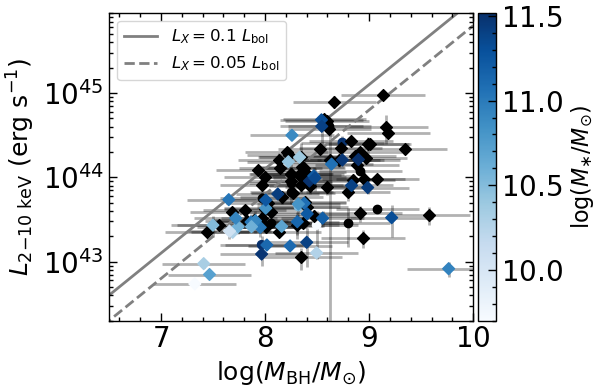

In [283]:
import scipy.constants as cst
nu_1keV = 1e3*cst.eV / cst.h

fig, ax = plt.subplots(1,1, figsize=(5, 4))
Eup = 10
Elo = 2

# Convert X-ray flux to luminosity  

#CHANDRA

Fx = (data_cosmos2020j[idx_chandra]['chandra.2to7'].data*u.mJy).to(u.erg/u.s/u.cm**2, equivalencies=u.spectral_density(4.5*u.keV)).value
Fx_err = (data_cosmos2020j[idx_chandra]['chandra.2to7_err'].data*u.mJy).to(u.erg/u.s/u.cm**2, equivalencies=u.spectral_density(4.5*u.keV)).value # mJy ->

# 
dL = cosmo.luminosity_distance(data_join['z_best'][idx_join]).to(u.cm).value
LX = (Fx*(4*np.pi*dL**2))
dLX = (Fx_err*(4*np.pi*dL**2))


mask = (data_join['M_line'][idx_join] > 0 ) & (LX > 0) & (dLX > 0)

ax.scatter(data_join['M_line'][idx_join][mask & ~mask_chi2], LX[mask & ~mask_chi2], marker='o', c='k')
im = ax.scatter(data_join['M_line'][idx_join][mask & mask_chi2], LX[mask & mask_chi2], marker='o',
                c=data_join['logMs'][idx_join][mask & mask_chi2], cmap='Blues')

ax.errorbar(data_join['M_line'][idx_join][mask], LX[mask], yerr=dLX[mask], xerr=0.4, linestyle='none', c='k', zorder=-1, alpha=0.3)


#XMM

Fx = (data_cosmos2020j[idx_chandra]['xmm.newton.0p2to12'].data*u.mJy).to(u.erg/u.s/u.cm**2, equivalencies=u.spectral_density(4.5*u.keV)).value
Fx_err = (data_cosmos2020j[idx_chandra]['xmm.newton.0p2to12_err'].data*u.mJy).to(u.erg/u.s/u.cm**2, equivalencies=u.spectral_density(4.5*u.keV)).value # mJy ->

# 
dL = cosmo.luminosity_distance(data_join['z_best'][idx_join]).to(u.cm).value
LX = (Fx*(4*np.pi*dL**2))
dLX = (Fx_err*(4*np.pi*dL**2))


mask = (data_join['M_line'][idx_join] > 0 ) & (LX > 0) & (dLX > 0)

ax.scatter(data_join['M_line'][idx_join][mask & ~mask_chi2], LX[mask & ~mask_chi2], marker='D', c='k')
im = ax.scatter(data_join['M_line'][idx_join][mask & mask_chi2], LX[mask & mask_chi2], marker='D',
                c=data_join['logMs'][idx_join][mask & mask_chi2], cmap='Blues')

ax.errorbar(data_join['M_line'][idx_join][mask], LX[mask], yerr=dLX[mask], xerr=0.4, linestyle='none', c='k', zorder=-1, alpha=0.3)





# L_bol = 10
x = np.linspace(6, 10)
L_Edd = 1.26*1e38*10**x #/ 10
ax.plot(x, 0.1*L_Edd / 10, label=r'$L_{X}{=}0.1\ L_{\rm{bol}}$', color='gray', zorder=-1)
ax.plot(x, 0.05*L_Edd / 10, label=r'$L_{X}{=}0.05\ L_{\rm{bol}}$', color='gray', zorder=-1, linestyle='dashed')
#ax.plot(x, 0.001*L_Edd, label=r'$L_{X}{=}10^{-3} L_{\rm{bol}}$', color='gray', zorder=-1, linestyle='dotted')

ax.legend(fontsize=12, frameon=True)


ax.set_yscale('log')
ax.set_xlabel(r'$\log(M_{\rm{BH}} / M_{\odot})$', fontsize=18)
ax.set_ylabel(r'$L_{2{-}10\ {\rm{keV}}}\ ({\rm{erg\ s}}^{-1}$)', fontsize=18)

ax.set_xlim(6.5, 10)
ax.set_ylim(2e42, 9e45)

divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.05)
fig.colorbar(im, cax=cax)
cax.set_ylabel(r'$\log(M_{\ast} / M_{\odot})$')

fig.savefig('xray.pdf', dpi=300)

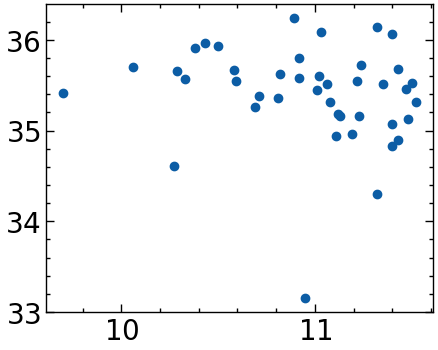

In [284]:
fig, ax = plt.subplots(1,1, figsize=(5, 4))

ax.scatter(data_join['logMs'][idx_join][mask & mask_chi2],
        np.log10(LX[mask & mask_chi2]/10**data_join['M_line'][idx_join][mask & mask_chi2]))

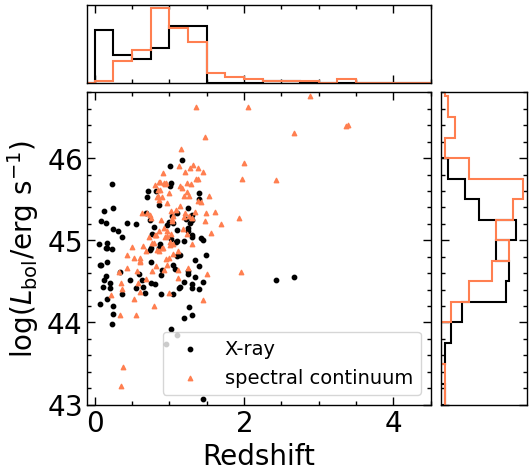

In [285]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

def scatter_hist(x, y, ax, ax_histx, ax_histy, color='k', marker='o', label=None):
    # no labels
    ax_histx.tick_params(axis="x", labelbottom=False)
    ax_histy.tick_params(axis="y", labelleft=False)

    # the scatter plot:
    ax.scatter(x, y, color=color, s=10, marker=marker, label=label)

    # now determine nice limits by hand:
    binwidth = 0.25
    xymax = max(np.nanmax(np.abs(x)), np.nanmax(np.abs(y)))
    lim = (int(xymax/binwidth) + 1) * binwidth

    bins = np.arange(-lim, lim + binwidth, binwidth)
    ax_histx.hist(x, bins=bins, histtype='step', lw=1.5, color=color)
    ax_histy.hist(y, bins=bins, orientation='horizontal', histtype='step', color=color, lw=1.5)

    ax_histx.get_yaxis().set_visible(False)
    ax_histy.get_xaxis().set_visible(False)

# Use 2-10
Eup = 10
Elo = 2

# Convert X-ray flux to luminosity  

#CHANDRA

Fx = (data_cosmos2020j[idx_chandra]['chandra.2to7'].data*u.mJy).to(u.erg/u.s/u.cm**2, equivalencies=u.spectral_density(4.5*u.keV)).value
Fx_err = (data_cosmos2020j[idx_chandra]['chandra.2to7_err'].data*u.mJy).to(u.erg/u.s/u.cm**2, equivalencies=u.spectral_density(4.5*u.keV)).value # mJy ->

# 
dL = cosmo.luminosity_distance(data_join['z_best'][idx_join]).to(u.cm).value
LX = (Fx*(4*np.pi*dL**2))
dLX = (Fx_err*(4*np.pi*dL**2))


mask = (data_join['M_line'][idx_join] > 0 ) & (LX > 0) & (dLX > 0)

ax.scatter(data_join['M_line'][idx_join][mask & ~mask_chi2], LX[mask & ~mask_chi2], marker='o', c='k')
im = ax.scatter(data_join['M_line'][idx_join][mask & mask_chi2], LX[mask & mask_chi2], marker='o',
                c=data_join['logMs'][idx_join][mask & mask_chi2], cmap='Blues')

ax.errorbar(data_join['M_line'][idx_join][mask], LX[mask], yerr=dLX[mask], xerr=0.4, linestyle='none', c='k', zorder=-1, alpha=0.3)


#XMM

Fx = (data_cosmos2020j[idx_chandra]['xmm.newton.0p2to12'].data*u.mJy).to(u.erg/u.s/u.cm**2, equivalencies=u.spectral_density(4.5*u.keV)).value
Fx_err = (data_cosmos2020j[idx_chandra]['xmm.newton.0p2to12_err'].data*u.mJy).to(u.erg/u.s/u.cm**2, equivalencies=u.spectral_density(4.5*u.keV)).value # mJy ->

# 
dL = cosmo.luminosity_distance(data_join['z_best'][idx_join]).to(u.cm).value
LX = (Fx*(4*np.pi*dL**2))
dLX = (Fx_err*(4*np.pi*dL**2))


mask = (data_join['M_line'][idx_join] > 0 ) & (LX > 0) & (dLX > 0)

ax.scatter(data_join['M_line'][idx_join][mask & ~mask_chi2], LX[mask & ~mask_chi2], marker='D', c='k')
im = ax.scatter(data_join['M_line'][idx_join][mask & mask_chi2], LX[mask & mask_chi2], marker='D',
                c=data_join['logMs'][idx_join][mask & mask_chi2], cmap='Blues')

ax.errorbar(data_join['M_line'][idx_join][mask], LX[mask], yerr=dLX[mask], xerr=0.4, linestyle='none', c='k', zorder=-1, alpha=0.3)

# Use 2-10


# Start with a square Figure.
fig = plt.figure(figsize=(5.5, 5))
# Add a gridspec with two rows and two columns and a ratio of 1 to 4 between
# the size of the marginal axes and the main axes in both directions.
# Also adjust the subplot parameters for a square plot.
gs = fig.add_gridspec(2, 2,  width_ratios=(4, 1), height_ratios=(1, 4),
                      left=0.1, right=0.9, bottom=0.1, top=0.9,
                      wspace=0.05, hspace=0.05)
# Create the Axes.
ax = fig.add_subplot(gs[1, 0])
ax_histx = fig.add_subplot(gs[0, 0], sharex=ax)
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax)
# Draw the scatter plot and marginals.
scatter_hist(data_agn_updated['z_best'][idx_join], np.log10(10*LX), ax, ax_histx, ax_histy, label='X-ray')

# Lbol
scatter_hist(data_join['z_best'].data, data_join['Lbol'].data, ax, ax_histx, ax_histy, color='coral', marker='^', label='Spectral Continuum')


ax.legend(loc=4, frameon=True, fontsize=14)
ax.set_xlabel('Redshift', fontsize=20)
ax.set_ylabel(r'$\log(L_{\rm{bol}} / {\rm erg\ s}^{-1})$', fontsize=20)

ax.set_xlim(-.1, 4.5)
ax.set_ylim(43, 46.8)


fig.tight_layout()
fig.savefig('Lbolredshift.pdf', dpi=300)

## SAVE

In [ ]:
data_sed = ascii.read('table_mass.dat')
data_classification = ascii.read('classification.txt', delimiter='|')
data_joint = table.join(data_sed, data_agn_BH_best, keys='ID', join_type='left')
data_joint = table.join(data_agn_updated, data_joint, keys='ID', join_type='left')
data_joint = table.join(data_classification, data_joint, keys='ID', join_type='right')

data_save = table.Table()
id = data_joint['ID']
ra = data_joint['RAdeg']
dec = data_joint['DEdeg']
i = data_joint['i-mag']
z_best = np.around(data_joint['z'], 4)
z_phot = data_joint['z_phot']
Lbol = np.around(data_joint['Lbol'],2)
logMs = data_joint['logMs']
logMs_e = data_joint['logMs_e']
SF_excess = data_joint['SF_excess']
chi2nu = data_joint['chi2']
M_line = np.around(data_joint['M_line'], 2)
M_line_e = np.around(data_joint['M_line_e'], 2)
classification = data_joint['Type']

# bad values

data_save = table.Table([id, ra, dec, i, z_best, z_phot, Lbol, M_line, M_line_e, logMs, logMs_e, SF_excess, chi2nu, classification],
                        names=['ID','RAdeg','DEdeg','i-mag','z_best','z_phot','logL','logMBH','logMBH_e','logMs','logMs_e','SF_excess','chi2nu', 'classification'])

data_save['logMBH'].fill_value = -1

data_save.write('prop.txt', overwrite=True, format='latex')
data_save

ID,RAdeg,DEdeg,i-mag,z_best,z_phot,logL,logMBH,logMBH_e,logMs,logMs_e,SF_excess,chi2nu,classification
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str26
1,150.74386,2.20245,22.71,1.58,1.58,--,--,--,10.62,0.4,1.13,3.0,--
2,150.73557,2.19957,20.36,3.5026,-1.0,46.68,9.04,0.11,11.16,0.4,0.9,2.9,BL
3,150.73353,2.15646,20.88,0.979,1.03,44.8,8.27,0.31,11.25,0.4,2.03,4.4,NeV
4,150.79702,2.13888,21.01,0.5727,0.51,--,--,--,10.96,0.4,3.29,1.3,--
5,150.78259,2.19306,20.63,0.5824,-1.0,--,--,--,--,--,--,--,BL
6,150.72019,2.24803,21.13,0.6652,0.62,44.89,8.04,0.0,10.87,0.4,1.96,0.5,BL
7,150.78838,2.34399,19.82,1.9555,2.0,--,--,--,10.16,0.4,1.31,8.8,BL
8,150.71511,2.48483,19.2,2.0051,-1.0,--,--,--,--,--,--,--,BL
9,150.71391,1.97214,22.87,0.3396,1.53,--,--,--,11.6,0.4,3.28,0.8,Noisy


In [ ]:
data_save['logMBH']

--
9.04
8.27
--
--
8.04
--
--
--
--
--


In [ ]:
data_sed = ascii.read('table_mass.txt')
data_classification = ascii.read('classification.txt', delimiter='|')
data_joint = table.join(data_sed, data_classification, keys='ID', join_type='left')

data_joint

ID,logMs,logMs_e,SF_excess,chi2,Type
int64,float64,float64,float64,float64,str26
1,10.64,0.12,1.1,3.0,--
2,11.53,0.13,0.8,1.9,BL
3,11.4,0.11,2.1,0.7,NeV
4,10.78,0.2,3.5,1.3,--
6,10.84,0.13,1.9,0.5,BL
7,10.52,0.1,1.0,7.8,BL
9,11.56,0.03,3.2,0.8,Noisy
10,11.08,0.05,1.6,3.1,Noisy?
11,10.71,0.06,1.7,6.7,NeV?
